# Hyperliquid block timing — distribution, dependence, forecastability, Binance lead

**Target:** Hyperliquid exchange block time (`ts_exch_ns`, integer ms), not arrival at the VM.

**What counts as "predictable" (Mark, 2026-10-18):**
1. the block interval can be modelled as some distribution,
2. there is autocorrelation,
3. the next block can be forecast *within a confidence interval* conditioned on previous blocks
   (e.g. a lot of trading in the previous block),
4. Binance activity *inside* HL's gaps leads what HL does next,
5. all of the above across the 6 instruments, comparing crypto perps vs tradfi (HIP-3 `xyz:`) perps.

**Status:** exploratory, *unregistered* (no hypothesis card yet). It was built before `qrlib` existed and hasn't been
migrated, so the card gate and the harness leakage gate don't run. This notebook carries its own truncation
test (§6) and a trial counter instead.

**The structural caveat that runs through everything:** the feed has no block height. A block is
only *visible* when at least one of the 6 subscribed instruments changed BBO or traded in it. Observed
gaps = (sum of k latent block intervals), k ≥ 1. Activity raises visibility, so "more activity → shorter
gaps" is partly a sampling artefact. Every activity result below is reported on **single-block gaps**
too, which is where the clock itself is measured.

## Summary (run of 2026-10-23: 48 h window 2026-10-18 03:14 → 10-20 03:14 UTC, 46.3 h covered in 21 segments; n_trials = 155)
**Weak points first**
* **The forecast skill levels and every tradfi number have not converged.** They moved well outside the 7.2 h CIs, because
  they depend on which session is in the sample. The window is Sunday + Monday, and the 60/40 split falls at **Mon 08:16 UTC**:
  train is mostly weekend, test is the Monday European + US sessions. The unconditional baseline F0 is therefore fit on a
  quieter regime than it is scored on, which flatters "skill vs F0". A day-by-day or weekday/weekend split would address it.
* The Monday US open is partly missing: feed holes 12:17–13:32 and 14:00–14:24 UTC.
* One sample of two days, one split. No block height in the feed (block counts are inferred). The HL↔Binance clock
  offset is unverified, and the `measured ts_recv` scenario assumes the VM and exchange clocks are in sync.
* The full ~89 h capture couldn't run on this machine (memory). This is the first 48 h, and it *contains* the earlier 7.2 h
  sample, so agreement with that run is not independent confirmation. The same 155 variants have now been evaluated twice.
* The Q3 bootstrap CIs treat autocorrelated gaps as independent (too narrow). The event-study jump threshold is a
  full-sample quantile (descriptive, not a tradeable rule).

| Question | 48 h result | 7.2 h (Sun am) | Converged? |
|---|---|---|---|
| Q1 distribution | Lattice: **67.0 ms clock (σ 1.8 ms)** carries 55% of blocks. Mean block 68.3 ms. Exponential badly wrong; every model formally rejected (n = 635k test). | 67.0 ms, σ 1.5, 65% | clock yes; core share moved |
| Q2 autocorrelation | Single-block **ρ(1) = −0.20** (rounding alone: −0.001); −0.18 to −0.21 per instrument. Raw-gap ρ(1) 0.17 is mostly visibility. | −0.20 | yes |
| Q3 activity | Doesn't move the clock: single-block next-gap medians 67 vs 67 ms everywhere. | same | yes |
| Q4 lags | OOS R² of log next gap 0.10 (union); crypto 0.11–0.14, **tradfi 0.23–0.29**. | 0.09; 0.08–0.22 | union yes; tradfi no |
| Q5 forecast, interval | Union skill vs unconditional **19.5% [19.2, 19.7]** at ~zero latency; **12.7% [12.5, 13.0]** on measured `ts_recv` (block known ~300 ms late). Across both scenarios, tradfi 24–28%, crypto 14–17%. | 14.1%; 10.7%; tradfi 5–17% | no |
| Binance in the gap | Timing: hazard gain ≤ 1.1% (union slightly *worse*), clock test |ρ| < 0.01. Price: HL reaches half a Binance jump 290 ms (HYPE) to 540 ms (BTC) later; 610 ms for SP500. | hazard tiny, clock null; 210–530 ms | timing yes; HYPE lag and tradfi lead no |

Findings in §12, then assumptions and open questions.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import statsmodels.api as sm
from scipy import optimize, stats
from scipy.special import expit, softmax
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import log_loss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

pa.set_memory_pool(pa.system_memory_pool())   # freed Arrow buffers go back to the OS (the default pool keeps them)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

# dataviz reference palette: slot 1 blue = crypto, slot 2 orange = tradfi, slot 3 aqua = model fits
C_CRYPTO, C_TRADFI, C_FIT, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "lines.linewidth": 2,
    "font.size": 9,
})

## 1. KNOBS
Every tunable choice lives here. `# ASSUMPTION:` marks choices Mark didn't specify.

In [2]:
DATA_ROOT = Path("../market_data_v2/normalized")
# Sample. Only windows where every input (HL l1 + trades for the 6 symbols, Binance l1 + trades for the 6 pairs) is fully
# synced from the VM. A new segment starts at each window edge, each reconnect and each feed hole, and no gap spans one.
DATA_WINDOWS = [("2026-10-18 03:14", "2026-10-20 03:14")]   # ASSUMPTION: first 48 h of capture (contains the earlier 7.2 h sample). The full ~89 h
                                                            # (to 10-21 20:31:43) needs ~15-20 GB and was stopped by the machine's memory limit twice.
MAX_HOLE_MS = 30_000    # ASSUMPTION: no visible block on any of the 6 instruments for 30 s = feed hole (union gaps are ~100 ms)

# HL symbol -> Binance USDT-perp. ASSUMPTION: xyz:SP500 is paired with Binance SPY (ETF ~ index/10;
# returns comparable, levels not). xyz:CL ~ CL-USDT, xyz:TSLA ~ TSLA-USDT.
PAIRS = {
    "BTC-USD-PERP": "BTC-USDT-PERP",
    "HYPE-USD-PERP": "HYPE-USDT-PERP",
    "AAVE-USD-PERP": "AAVE-USDT-PERP",
    "xyz:SP500-USD-PERP": "SPY-USDT-PERP",
    "xyz:TSLA-USD-PERP": "TSLA-USDT-PERP",
    "xyz:CL-USD-PERP": "CL-USDT-PERP",
}
GROUP = {s: ("tradfi" if s.startswith("xyz:") else "crypto") for s in PAIRS}
SYMS = list(PAIRS)

TRAIN_FRAC = 0.6        # ASSUMPTION: chronological 60/40 split by HL block time; no shuffling.
GMAX = 600              # ASSUMPTION: distribution fits use gaps <= 600 ms (covers ~99% of union gaps).
KMAX = 8                # max latent blocks per observed gap in the lattice model.
SINGLE_POST = 0.90      # ASSUMPTION: a gap is "single-block" if P(k=1 | gap) >= 0.90 under the train fit.
ACF_LAGS = 20
LB_LAGS = [1, 5, 10, 20]
HAC_LAGS = 20           # Newey-West lags for Wald tests.
ACT_HIGH_Q = 0.80       # ASSUMPTION: "high activity" = top quintile of the activity measure (train cut).
QUANTILES = [0.1, 0.5, 0.9]   # forecast interval = [q10, q90], nominal 80% coverage.
HGB_KW = dict(max_iter=200, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200,
              early_stopping=False, random_state=0)   # ASSUMPTION: fixed, untuned (no tuning = fewer trials).
BOOT_REPS, BOOT_BLOCK = 400, 500   # moving-block bootstrap on test losses (block = 500 consecutive obs).
HAZ_STEP, HAZ_TMAX = 10, 600       # within-gap hazard grid (ms).
# Latency = time from an exchange timestamp until we *know* the event. Only the forecasting section (Q5) uses it:
# a forecast made "at block n" can only use what has arrived by then. Q1-Q4, the hazard and the lead analysis stay
# pure exchange-time descriptions of the process. Two scenarios are run side by side:
LATENCY_SCENARIOS = {
    # Mark's figure (2026-10-19) for HL block latency only. Binance events count at their exchange time (bn=None). Until
    # 2026-10-21 the same N(0.50, 0.05) was also applied to Binance (an agent extension, no numerical effect at 1 ms resolution).
    "N(0.50, 0.05) ms": dict(kind="normal", hl=(0.50, 0.05), bn=None),
    # Each message's actual arrival on the VM (ts_recv). ASSUMPTION: VM clock and exchange clocks are in sync.
    "measured ts_recv": dict(kind="recv"),
}
LEAD_SHIFTS = np.arange(-1000, 501, 10)  # price-lead profile shifts (ms, Binance relative to HL).
WITHIN_DELTAS = [10, 30, 60]       # Binance return measured up to (next HL update - delta).
EVT_RET_MS = 50          # event study: a Binance "jump" = |mid return over 50 ms| ...
EVT_Q = 0.995            # ... in the top 0.5% for that pair. ASSUMPTION: threshold picked to get ~100s of events.
EVT_MIN_SEP = 2000       # keep jumps >= 2 s apart so the windows don't overlap.
EVT_WIN = np.arange(-1000, 2001, 10)   # ms around the jump.
SEED = 0

TRIALS = []   # every evaluated model variant is appended here; n_trials reported at the end.
def log_trial(**kw):
    TRIALS.append(kw)

## 2. Data
* HL `l1` (= `bbo` channel, event-driven) and `trades` for the 6 symbols. `l2` is ~5.4 s snapshots → unused.
* HL trades replay a snapshot on every (re)subscribe; rows executed before their connection opened are dropped.
  The same filter is applied to `l1`.
* Binance: `l1` uses `ts_txn_ns` (bookTicker `T`, matching-engine time); trades use `ts_trade_ns` (`T`).
  ASSUMPTION: `T` is the closest Binance analogue to HL block time. Binance trade `E` lags `T` by ~150 ms.

In [3]:
def _in_windows(col, typ):
    f = None
    for a, b in DATA_WINDOWS:   # bounds in the column's own type (Binance ts_txn_ns is stored as double)
        lo, hi = (pa.scalar(float(v) if pa.types.is_floating(typ) else v, typ) for v in (pd.Timestamp(a).value, pd.Timestamp(b).value))
        e = (ds.field(col) >= lo) & (ds.field(col) < hi)
        f = e if f is None else f | e
    return f

def load(table, venue, cols, ts_col, syms, derive=None, sort_t=False):
    """Rows of `syms` inside DATA_WINDOWS, read one symbol at a time into preallocated columns (Binance BTC l1 is ~1.4M
    rows/h, so the raw columns don't fit in memory at once). `derive(batch) -> {name: array}` keeps only what's needed.
    Each symbol is a contiguous block of rows; `df.attrs["rows"][sym]` is its slice. sort_t sorts each block by `t` in place,
    so streams can be views of the frame instead of copies.
    The collector renamed the `xyz:` folders to `xyz_`; the old copies (':' written as U+F03A) duplicate the first 9 h
    and are skipped."""
    derive = derive or (lambda b: {c: b.column(c).to_numpy(zero_copy_only=False) for c in cols})
    base = DATA_ROOT / f"table={table}" / f"venue={venue}"
    sets = {}
    for s in syms:
        files = [str(f) for f in (base / f"symbol={s.replace(':', '_')}").rglob("*.parquet")]   # skips in-flight *.partial files
        d = ds.dataset(files, format="parquet")
        flt = _in_windows(ts_col, d.schema.field(ts_col).type)
        sets[s] = (d, flt, d.count_rows(filter=flt))
    n = sum(v[2] for v in sets.values())
    out, codes, rows, i = None, np.empty(n, np.int8), {}, 0
    for k, (s, (d, flt, ns)) in enumerate(sets.items()):
        a = i
        for b in d.to_batches(columns=cols, filter=flt):
            m = b.num_rows
            if m == 0:
                continue
            new = derive(b)
            out = out or {c: np.empty(n, v.dtype) for c, v in new.items()}
            for c, v in new.items():
                out[c][i:i + m] = v
            i += m
        assert i - a == ns
        codes[a:i] = k
        rows[s] = slice(a, i)
        if sort_t and i > a:
            o = np.argsort(out["t"][a:i], kind="stable")
            for c in out:
                out[c][a:i] = out[c][a:i][o]
            del o
    df = pd.DataFrame(out, copy=False)
    df["symbol"] = pd.Categorical.from_codes(codes, categories=syms)
    df.attrs["rows"] = rows
    del sets
    pa.default_memory_pool().release_unused()
    return df

sess = ds.dataset([str(f) for f in (DATA_ROOT / "table=sessions").rglob("*.parquet")], format="parquet", partitioning="hive",
                  partition_base_dir=str(DATA_ROOT / "table=sessions")).to_table().to_pandas()   # *.parquet skips in-flight sync files
hl_open = (sess[(sess.venue == "HYPERLIQUID") & (sess.kind == "ws") & (~sess.resumed)]
           .groupby("ordinal").opened_ns.min())
print("HL ws connections (ordinal -> opened):", {k: str(pd.to_datetime(v)) for k, v in hl_open.items()})

hl_l1 = load("l1", "HYPERLIQUID", ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "bid_px", "ask_px"], "ts_exch_ns", SYMS)
hl_tr = load("trades", "HYPERLIQUID", ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "price", "size"], "ts_exch_ns", SYMS)
for df in (hl_l1, hl_tr):
    df["symbol"] = df.symbol.astype(str)     # small tables: plain strings, so groupbys behave as before

def drop_replays(df, name):
    opened = df.conn_ordinal.map(hl_open)
    bad = df.ts_exch_ns < opened
    print(f"{name}: dropped {bad.sum()} rows executed before their connection opened (subscribe replay)")
    return df[~bad].copy()

hl_l1 = drop_replays(hl_l1, "HL l1")
hl_tr = drop_replays(hl_tr, "HL trades")
for df in (hl_l1, hl_tr):
    df["t"] = df.ts_exch_ns // 1_000_000           # integer ms, exact (feed is ms resolution)
hl_l1["lmid"] = np.log((hl_l1.bid_px + hl_l1.ask_px) / 2)
hl_tr["notional"] = hl_tr.price * hl_tr.size

BN = list(PAIRS.values())
bn_l1 = load("l1", "BINANCE_FUTURES", ["ts_txn_ns", "ts_recv_ns", "bid_px", "ask_px"], "ts_txn_ns", BN, sort_t=True, derive=lambda b: {
    "t": np.round(b.column("ts_txn_ns").to_numpy() / 1e6).astype("int64"),
    "recv": b.column("ts_recv_ns").to_numpy() / 1e6,
    "lmid": np.log((b.column("bid_px").to_numpy() + b.column("ask_px").to_numpy()) / 2)})
bn_tr = load("trades", "BINANCE_FUTURES", ["ts_trade_ns", "ts_recv_ns"], "ts_trade_ns", BN, derive=lambda b: {
    "t": b.column("ts_trade_ns").to_numpy() // 1_000_000, "recv": b.column("ts_recv_ns").to_numpy() / 1e6})
for df in (hl_l1, hl_tr):
    df["recv"] = df.ts_recv_ns / 1e6            # VM arrival, float ms (used only by the latency scenarios)

# Segments: a new one starts at every reconnect, DATA_WINDOWS edge and union hole > MAX_HOLE_MS. The segment id replaces
# conn_ordinal from here on, so no gap, pair of updates or forecast target spans a break.
u = pd.concat([hl_l1[["t", "conn_ordinal"]], hl_tr[["t", "conn_ordinal"]]]).groupby("t").conn_ordinal.min()
tv, cv = u.index.values, u.values
win = np.searchsorted([pd.Timestamp(a).value // 1_000_000 for a, _ in DATA_WINDOWS], tv, "right")
brk = np.r_[True, (cv[1:] != cv[:-1]) | (win[1:] != win[:-1]) | (np.diff(tv) > MAX_HOLE_MS)]
SEG_START, SEG_END = tv[brk], np.r_[tv[np.flatnonzero(brk)[1:] - 1], tv[-1]]
for df in (hl_l1, hl_tr):
    df["conn_ordinal"] = np.searchsorted(SEG_START, df.t.values, "right") - 1

def same_segment(a, b):
    """True where times a <= b fall inside one segment."""
    i, j = np.searchsorted(SEG_START, a, "right") - 1, np.searchsorted(SEG_START, b, "right") - 1
    return (i == j) & (i >= 0) & (b <= SEG_END[np.clip(j, 0, None)])

print(pd.DataFrame({"from": pd.to_datetime(SEG_START, unit="ms"), "to": pd.to_datetime(SEG_END, unit="ms"),
                    "hours": (SEG_END - SEG_START) / 3.6e6}).round(2).to_string())
print(f"covered {(SEG_END - SEG_START).sum() / 3.6e6:.2f} h in {len(SEG_START)} segments")

span = pd.to_datetime([hl_l1.t.min(), hl_l1.t.max()], unit="ms")
print(f"HL span {span[0]} -> {span[1]}  ({(span[1]-span[0]).total_seconds()/3600:.2f} h, "
      f"weekday={span[0].day_name()})")
print(pd.DataFrame({
    "HL l1": hl_l1.symbol.value_counts(), "HL trades": hl_tr.symbol.value_counts(),
    "BN l1": bn_l1.symbol.map({v: k for k, v in PAIRS.items()}).value_counts(),
    "BN trades": bn_tr.symbol.map({v: k for k, v in PAIRS.items()}).value_counts(),
}).loc[SYMS])

HL ws connections (ordinal -> opened): {1: '2026-10-18 03:14:20.942266703', 2: '2026-10-18 06:11:48.873706341', 3: '2026-10-18 09:06:28.603243589', 4: '2026-10-18 11:56:09.339513302', 5: '2026-10-18 14:52:53.725256205', 6: '2026-10-18 16:23:15.223858118', 7: '2026-10-18 18:57:02.734971762', 8: '2026-10-18 19:13:21.609763861', 9: '2026-10-18 19:32:38.046205282', 10: '2026-10-18 22:33:56.401937246', 11: '2026-10-19 01:32:03.017298460', 12: '2026-10-19 04:30:50.839010239', 13: '2026-10-19 07:17:41.933292389', 14: '2026-10-19 10:13:42.438862324', 15: '2026-10-21 07:13:19.159312487', 16: '2026-10-21 10:01:12.300660849', 17: '2026-10-21 12:53:55.884192944', 18: '2026-10-21 15:44:02.070926428', 19: '2026-10-21 18:36:32.178644896'}


HL l1: dropped 32 rows executed before their connection opened (subscribe replay)


HL trades: dropped 0 rows executed before their connection opened (subscribe replay)


                      from                      to  hours
0  2026-10-18 03:14:20.960 2026-10-18 06:11:48.315   2.96
1  2026-10-18 06:11:48.934 2026-10-18 09:06:27.997   2.91
2  2026-10-18 09:06:28.741 2026-10-18 11:56:08.708   2.83
3  2026-10-18 11:56:09.445 2026-10-18 14:52:53.036   2.95
4  2026-10-18 14:52:53.804 2026-10-18 16:22:54.447   1.50
5  2026-10-18 16:23:15.244 2026-10-18 18:56:47.328   2.56
6  2026-10-18 18:57:02.772 2026-10-18 19:13:06.398   0.27
7  2026-10-18 19:13:21.675 2026-10-18 19:32:36.503   0.32
8  2026-10-18 19:32:38.060 2026-10-18 22:33:55.736   3.02
9  2026-10-18 22:33:56.457 2026-10-19 01:32:02.463   2.97
10 2026-10-19 01:32:03.074 2026-10-19 04:30:50.344   2.98
11 2026-10-19 04:30:50.881 2026-10-19 07:17:41.290   2.78
12 2026-10-19 07:17:42.379 2026-10-19 10:13:41.805   2.93
13 2026-10-19 10:13:42.486 2026-10-19 12:00:49.715   1.79
14 2026-10-19 12:01:00.445 2026-10-19 12:16:54.998   0.27
15 2026-10-19 13:32:32.878 2026-10-19 14:00:02.086   0.46
16 2026-10-19 

                      HL l1  HL trades     BN l1  BN trades
symbol                                                     
BTC-USD-PERP        1035528     466437  62997875    1754635
HYPE-USD-PERP        844227     403940  11160685     754548
AAVE-USD-PERP        500101      31867   3196268     211705
xyz:SP500-USD-PERP   343398     117777   2263847      46738
xyz:TSLA-USD-PERP    292496     120874   3584147     239940
xyz:CL-USD-PERP      414832     102207   4040615     119492


### 2.1 Block table
A *visible block* = a distinct HL `t` (ms) carrying any l1 update or trade on any of the 6 symbols.
Gaps that span a reconnect are dropped (the outage would masquerade as a long block).

In [4]:
ev = pd.concat([
    hl_l1[["symbol", "t", "recv", "conn_ordinal"]].assign(n_l1=1, n_tr=0, notional=0.0),
    hl_tr[["symbol", "t", "recv", "conn_ordinal", "notional"]].assign(n_l1=0, n_tr=1),
], ignore_index=True)
blk_recv = ev.groupby("t").recv.max()   # a block is fully known once its last message has arrived
ev["grp"] = ev.symbol.map(GROUP)

blk = ev.groupby("t").agg(n_l1=("n_l1", "sum"), n_tr=("n_tr", "sum"), notional=("notional", "sum"),
                          n_sym=("symbol", "nunique"), ordinal=("conn_ordinal", "min"))
grp_cnt = ev.groupby(["t", "grp"]).size().unstack(fill_value=0)
blk["upd_crypto"] = grp_cnt.get("crypto", 0)
blk["upd_tradfi"] = grp_cnt.get("tradfi", 0)
blk = blk.reset_index()
blk["gap"] = blk.t.diff()
blk.loc[blk.ordinal != blk.ordinal.shift(), "gap"] = np.nan   # first block / reconnect-spanning gap
print(f"visible blocks: {len(blk):,}; valid gaps: {blk.gap.notna().sum():,}")

# per-instrument update streams: distinct t where that symbol updated (l1 or trade)
inst = {}
for s in SYMS:
    e = ev[ev.symbol == s].groupby("t").agg(n_l1=("n_l1", "sum"), n_tr=("n_tr", "sum"),
                                             notional=("notional", "sum"), ordinal=("conn_ordinal", "min")).reset_index()
    e["gap"] = e.t.diff()
    e.loc[e.ordinal != e.ordinal.shift(), "gap"] = np.nan
    inst[s] = e

T_SPLIT = blk.t.quantile(TRAIN_FRAC)
print("train/test split at", pd.to_datetime(T_SPLIT, unit="ms"))

visible blocks: 1,590,129; valid gaps: 1,590,108


train/test split at 2026-10-19 08:16:41.269600098


### 2.2 Do all 6 instruments share one block clock?
If the HIP-3 `xyz:` dex ran on a different clock, its timestamps wouldn't coincide with main-dex ones.

In [5]:
tsets = {s: set(inst[s].t) for s in SYMS}
rows = []
for s in SYMS:
    others = set().union(*[tsets[o] for o in SYMS if o != s])
    other_grp = set().union(*[tsets[o] for o in SYMS if GROUP[o] != GROUP[s]])
    rows.append({"symbol": s, "group": GROUP[s], "visible_blocks": len(tsets[s]),
                 "share_of_union": len(tsets[s]) / len(blk),
                 "ts_shared_with_any_other": len(tsets[s] & others) / len(tsets[s]),
                 "ts_shared_with_other_group": len(tsets[s] & other_grp) / len(tsets[s])})
clock = pd.DataFrame(rows).set_index("symbol")
clock

,group,visible_blocks,share_of_union,ts_shared_with_any_other,ts_shared_with_other_group
symbol,,,,,
BTC-USD-PERP,crypto,1036637,0.6519,0.7731,0.4620
HYPE-USD-PERP,crypto,845133,0.5315,0.8112,0.4595
AAVE-USD-PERP,crypto,500241,0.3146,0.8910,0.4978
xyz:SP500-USD-PERP,tradfi,343870,0.2163,0.8812,0.8191
xyz:TSLA-USD-PERP,tradfi,292950,0.1842,0.9069,0.8456
xyz:CL-USD-PERP,tradfi,415219,0.2611,0.8585,0.8039


## 3. Q1 — Is the block interval consistent with a distribution?

**H0:** observed gaps follow F(θ). Candidates, all fit by ML on the **train** histogram (gaps ≤ GMAX) and scored on **test**:
* **M0 exponential** — memoryless (Poisson block arrivals). The "no clock" null.
* **M1 shifted lognormal** — a smooth single-mode duration, no lattice.
* **M2a lattice, rigid clock** — gap = sum of k blocks, each block ~ Normal(μ, σ) (σ absorbs ms rounding); k has free weights.
* **M2b lattice, clock + slow blocks** — block ~ π·Normal(μ, σ) + (1−π)·(shift + Gamma). The Gamma part lets some
  blocks run long (or short) without needing a skipped block.

ASSUMPTION: k (how many blocks were invisible) is independent of the block durations. It isn't exactly — a long block
has more time to accumulate a visible change — so k-weights are descriptive, not structural.

In [6]:
grid = np.arange(GMAX + 1, dtype=float)

def _disc(cdf):
    p = cdf(grid + 0.5) - cdf(grid - 0.5)
    p[0] = 0.0
    return np.clip(p, 0, None)

def block_pmf(th, rigid):
    mu, lsig = th[0], th[1]
    core = _disc(lambda x: stats.norm.cdf(x, mu, np.exp(lsig)))
    if rigid:
        b = core
    else:
        pi, shift, a, sc = expit(th[2]), th[3], np.exp(th[4]), np.exp(th[5])
        tail = _disc(lambda x: stats.gamma.cdf(x - shift, a, scale=sc))
        b = pi * core + (1 - pi) * tail
    return b / b.sum()

def lattice_pmf(th, rigid, return_k=False):
    nb = 2 if rigid else 6
    b, w = block_pmf(th[:nb], rigid), softmax(th[nb:])
    comps, bk = [], b.copy()
    for k in range(KMAX):
        comps.append(w[k] * bk)
        bk = np.convolve(bk, b)[: GMAX + 1]
    comps = np.array(comps)
    tot = comps.sum(0)
    z = tot.sum()
    return (comps / z, tot / z) if return_k else tot / z

MODELS = {
    "M0 exponential": dict(n=1, x0=[np.log(150.0)],
                           pmf=lambda th: (lambda p: p / p.sum())(_disc(lambda x: stats.expon.cdf(x, scale=np.exp(th[0]))))),
    "M1 shifted lognormal": dict(n=3, x0=[30.0, np.log(60.0), np.log(0.8)],
                                 pmf=lambda th: (lambda p: p / p.sum())(_disc(lambda x: stats.lognorm.cdf(x - th[0], np.exp(th[2]), scale=np.exp(th[1]))))),
    "M2a lattice rigid": dict(n=2 + KMAX, x0=[67.0, np.log(1.5)] + list(-0.5 * np.arange(KMAX)),
                              pmf=lambda th: lattice_pmf(th, rigid=True)),
    "M2b lattice + slow blocks": dict(n=6 + KMAX, x0=[67.0, np.log(1.5), 0.0, 40.0, np.log(2.0), np.log(15.0)] + list(-0.5 * np.arange(KMAX)),
                                      pmf=lambda th: lattice_pmf(th, rigid=False)),
}

def hist(g):
    g = g[(g >= 0) & (g <= GMAX)].astype(int)
    return np.bincount(g, minlength=GMAX + 1).astype(float)

def nll(th, pmf, counts):
    return -(counts * np.log(pmf(th) + 1e-300)).sum()

def fit_all(gaps_train, gaps_test, label):
    htr, hte = hist(gaps_train), hist(gaps_test)
    out, fits = [], {}
    for name, m in MODELS.items():
        r = optimize.minimize(nll, m["x0"], args=(m["pmf"], htr), method="L-BFGS-B")
        if "lattice" in name:   # second start from a wider clock to avoid a bad local optimum
            x1 = np.array(m["x0"], float); x1[1] = np.log(3.0)
            r2 = optimize.minimize(nll, x1, args=(m["pmf"], htr), method="L-BFGS-B")
            r = r2 if r2.fun < r.fun else r
        fits[name] = r.x
        p = m["pmf"](r.x)
        exp_te = hte.sum() * p
        cdf_gap = np.abs(np.cumsum(hte) / hte.sum() - np.cumsum(p)).max()
        # chi-square GOF on test, bins merged until expected >= 5
        o, e, ob, eb = [], [], 0.0, 0.0
        for oi, ei in zip(hte, exp_te):
            ob += oi; eb += ei
            if eb >= 5:
                o.append(ob); e.append(eb); ob = eb = 0.0
        if o:
            o[-1] += ob; e[-1] += eb
        chi2 = (((np.array(o) - np.array(e)) ** 2) / np.array(e)).sum()
        dof = len(o) - 1 - m["n"]
        out.append({"set": label, "model": name, "k_params": m["n"],
                    "train_nll_per_obs": r.fun / htr.sum(),
                    "test_nll_per_obs": nll(r.x, m["pmf"], hte) / hte.sum(),
                    "test_AIC": 2 * nll(r.x, m["pmf"], hte) + 2 * m["n"],
                    "chi2/dof": chi2 / dof, "GOF p": stats.chi2.sf(chi2, dof), "max|CDF diff|": cdf_gap,
                    "n_train": int(htr.sum()), "n_test": int(hte.sum())})
        log_trial(q="Q1", set=label, model=name)
    return pd.DataFrame(out), fits

g_all = blk.gap.dropna()
is_tr = blk.t <= T_SPLIT
q1_tab, q1_fits = fit_all(blk.gap[is_tr].dropna().values, blk.gap[~is_tr].dropna().values, "union")
q1_tab.set_index("model").drop(columns="set")

,k_params,train_nll_per_obs,test_nll_per_obs,test_AIC,chi2/dof,GOF p,max|CDF diff|,n_train,n_test
model,,,,,,,,,
M0 exponential,1,5.6685,5.5749,7.0843e+06,4200.9528,0.0,0.3574,951079,635377
M1 shifted lognormal,3,5.1091,4.9598,6.3027e+06,1677.6400,0.0,0.1971,951079,635377
M2a lattice rigid,10,4.8176,4.6852,5.9538e+06,754.1053,0.0,0.1114,951079,635377
M2b lattice + slow blocks,14,4.6349,4.5681,5.8049e+06,242.2523,0.0,0.0890,951079,635377


In [7]:
th = q1_fits["M2b lattice + slow blocks"]
mu, sig, pi = th[0], np.exp(th[1]), expit(th[2])
bpmf = block_pmf(th[:6], rigid=False)
comps, tot = lattice_pmf(th, rigid=False, return_k=True)
post1 = comps[0] / np.maximum(tot, 1e-300)
# single-block threshold: last ms (after the core) where P(k=1|gap) is still >= SINGLE_POST
mode = int(np.argmax(bpmf))
thr_hi = mode + int(np.argmax(post1[mode:] < SINGLE_POST)) - 1
thr_lo = 1
SINGLE_MAX = thr_hi
w = softmax(th[6:])
bmean = (grid * bpmf).sum()
print(f"M2b block clock: core mu={mu:.2f} ms, sigma={sig:.2f} ms, share of blocks on the core={pi:.1%}")
print(f"implied mean block = {bmean:.1f} ms  -> {1000/bmean:.2f} blocks/s;  block-pmf median = {np.searchsorted(np.cumsum(bpmf), .5)} ms")
print("P(k) among gaps <= GMAX:", {k + 1: round(float(x), 3) for k, x in enumerate(w)})
print(f"single-block gaps: gap <= {SINGLE_MAX} ms (P(k=1|gap) >= {SINGLE_POST})")
blocks_seen = len(blk) / ((blk.t.max() - blk.t.min()) / bmean)
print(f"visible blocks / implied blocks = {blocks_seen:.1%}")

M2b block clock: core mu=66.96 ms, sigma=1.82 ms, share of blocks on the core=55.2%
implied mean block = 68.3 ms  -> 14.64 blocks/s;  block-pmf median = 67 ms
P(k) among gaps <= GMAX: {1: 0.618, 2: 0.268, 3: 0.074, 4: 0.018, 5: 0.011, 6: 0.007, 7: 0.002, 8: 0.002}
single-block gaps: gap <= 100 ms (P(k=1|gap) >= 0.9)
visible blocks / implied blocks = 62.9%


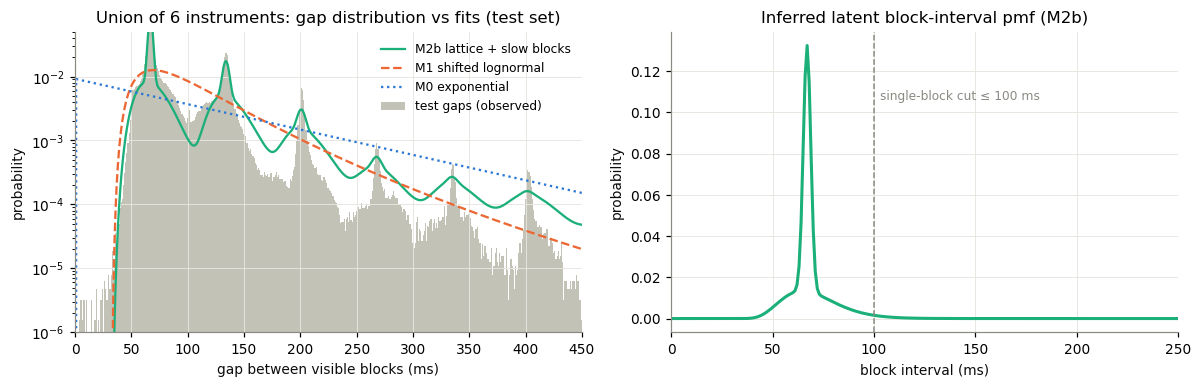

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
hte = hist(blk.gap[~is_tr].dropna().values)
x = grid
ax[0].bar(x, hte / hte.sum(), width=1.0, color="#c3c2b7", label="test gaps (observed)")
for name, ls, col in [("M2b lattice + slow blocks", "-", C_FIT), ("M1 shifted lognormal", "--", C_TRADFI), ("M0 exponential", ":", C_CRYPTO)]:
    ax[0].plot(x, MODELS[name]["pmf"](q1_fits[name]), ls, color=col, lw=1.5, label=name)
ax[0].set(xlim=(0, 450), yscale="log", ylim=(1e-6, 0.05), xlabel="gap between visible blocks (ms)", ylabel="probability",
          title="Union of 6 instruments: gap distribution vs fits (test set)")
ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(x, bpmf, color=C_FIT, label="fitted single-block interval")
ax[1].axvline(SINGLE_MAX, color=C_MUTED, lw=1, ls="--")
ax[1].text(SINGLE_MAX + 3, bpmf.max() * 0.8, f"single-block cut ≤ {SINGLE_MAX} ms", color=C_MUTED, fontsize=8)
ax[1].set(xlim=(0, 250), xlabel="block interval (ms)", ylabel="probability", title="Inferred latent block-interval pmf (M2b)")
plt.tight_layout(); plt.show()

### 3.1 Per instrument
Each instrument only sees the blocks where *it* changed. Gaps in **block units** (gap / mean block) show how much
of the clock each instrument observes. The clock is chain-wide, so differences here are about *visibility*, not timing.

In [9]:
rows = []
for s in SYMS:
    g = inst[s].gap.dropna()
    k = np.round(g / bmean)
    rows.append({"symbol": s, "group": GROUP[s], "n_gaps": len(g), "median gap ms": g.median(),
                 "p90 gap ms": g.quantile(.9), "share single-block (≤cut)": (g <= SINGLE_MAX).mean(),
                 "median k (blocks)": k.median(), "share of all blocks visible": len(inst[s]) / ((inst[s].t.max() - inst[s].t.min()) / bmean)})
q1_inst = pd.DataFrame(rows).set_index("symbol")
q1_inst

,group,n_gaps,median gap ms,p90 gap ms,share single-block (≤cut),median k (blocks),share of all blocks visible
symbol,,,,,,,
BTC-USD-PERP,crypto,1036616,112.0,333.0,0.4752,2.0,0.4098
HYPE-USD-PERP,crypto,845112,122.0,399.0,0.4456,2.0,0.3341
AAVE-USD-PERP,crypto,500220,140.0,674.0,0.3201,2.0,0.1977
xyz:SP500-USD-PERP,tradfi,343849,199.0,1032.0,0.2723,3.0,0.1359
xyz:TSLA-USD-PERP,tradfi,292929,147.0,1074.0,0.3143,2.0,0.1158
xyz:CL-USD-PERP,tradfi,415198,136.0,637.0,0.3456,2.0,0.1641


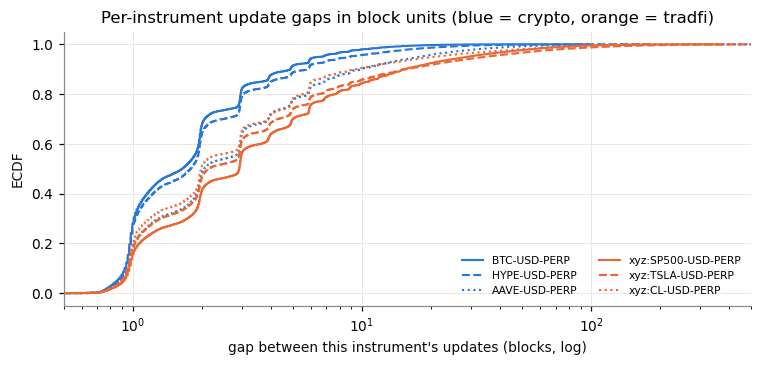

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s in SYMS:
    g = inst[s].gap.dropna().values / bmean
    xs = np.sort(g); ys = np.arange(1, len(xs) + 1) / len(xs)
    ax.plot(xs, ys, color=C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI, lw=1.4,
            ls="-" if s in ("BTC-USD-PERP", "xyz:SP500-USD-PERP") else ("--" if s in ("HYPE-USD-PERP", "xyz:TSLA-USD-PERP") else ":"),
            label=s)
ax.set(xscale="log", xlim=(0.5, 500), xlabel="gap between this instrument's updates (blocks, log)", ylabel="ECDF",
       title="Per-instrument update gaps in block units (blue = crypto, orange = tradfi)")
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 4. Q2 — Are intervals independent?
**H0:** ρ(k) = 0. Three series, because raw gaps mix the clock with visibility:
* **raw gap** (union) — what you observe,
* **k = round(gap / mean block)** — the visibility process (how many blocks were skipped),
* **single-block gap** — the clock itself; non-single gaps are set to NaN and ACF uses pairwise-complete lags.

With n ≈ 200k, ±1.96/√n ≈ ±0.004: tiny ρ will be "significant". Read the magnitude.

In [11]:
def acf_nan(x, nlags):
    x = np.asarray(x, float); m = np.nanmean(x); x = x - m
    v = np.nanmean(x * x)
    out, ns = [], []
    for k in range(1, nlags + 1):
        a, b = x[:-k], x[k:]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.mean(a[ok] * b[ok]) / v); ns.append(ok.sum())
    return np.array(out), np.array(ns)

def lb_from_acf(r, n, lags):
    res = {}
    for L in lags:
        q = n * (n + 2) * np.sum(r[:L] ** 2 / (n - np.arange(1, L + 1)))
        res[L] = (q, stats.chi2.sf(q, L))
    return res

def q2_series(g):
    g = pd.Series(g).dropna().values   # reconnect gaps removed; series stitched (2 joins, negligible)
    single = np.where(g <= SINGLE_MAX, g, np.nan)
    return {"raw gap": g, "log raw gap": np.log(g), "k (skipped blocks)": np.round(g / bmean), "single-block gap": single}

rows, acfs = [], {}
for name, sser in q2_series(blk.gap).items():
    r, ns = acf_nan(sser, ACF_LAGS)
    lb = lb_from_acf(r, int(np.median(ns)), LB_LAGS)
    acfs[name] = r
    rows.append({"series": name, "n": int(np.sum(~np.isnan(sser))), **{f"rho({k})": r[k - 1] for k in (1, 2, 5, 10)},
                 **{f"LB({L}) p": lb[L][1] for L in LB_LAGS}})
q2_union = pd.DataFrame(rows).set_index("series")
print(f"±1.96/sqrt(n) band ≈ ±{1.96/np.sqrt(len(blk)):.4f}")
q2_union

±1.96/sqrt(n) band ≈ ±0.0016


,n,rho(1),rho(2),rho(5),rho(10),LB(1) p,LB(5) p,LB(10) p,LB(20) p
series,,,,,,,,,
raw gap,1590108,0.1697,0.2160,0.1339,0.1051,0.0,0.0,0.0,0.0
log raw gap,1590108,0.1015,0.2395,0.1214,0.1043,0.0,0.0,0.0,0.0
k (skipped blocks),1590108,0.1541,0.2161,0.1289,0.1026,0.0,0.0,0.0,0.0
single-block gap,986783,-0.2036,0.0323,0.0237,0.0139,0.0,0.0,0.0,0.0


**Is the negative ρ(1) on single-block gaps just ms rounding?** Each timestamp is rounded to the ms; a rounding error
e_n enters gap n with + and gap n+1 with −, giving ρ(1) ≈ −Var(e)/Var(gap) with Var(e) = 1/12 ms². If the observed ρ(1)
is far below that, it's a real clock property: a block stamped late is followed by one stamped early (jitter around a
schedule / catch-up), which makes the next single-block interval partly predictable.

In [12]:
sg = q2_series(blk.gap)["single-block gap"]
v = np.nanvar(sg)
print(f"Var(single-block gap) = {v:.2f} ms^2 -> rounding-only rho(1) ≈ {-(1/12)/v:.4f}; observed {q2_union.loc['single-block gap','rho(1)']:.4f}")
a, b = sg[:-1], sg[1:]
ok = ~np.isnan(a) & ~np.isnan(b)
pairs_df = pd.DataFrame({"prev": a[ok], "next": b[ok]})
pairs_df["prev_bin"] = pd.cut(pairs_df.prev, [0, 55, 62, 65, 66, 67, 68, 69, 72, 80, 100])
pairs_df.groupby("prev_bin", observed=True).next.agg(["count", "median", "mean"]).round(2)

Var(single-block gap) = 91.04 ms^2 -> rounding-only rho(1) ≈ -0.0009; observed -0.2036


,count,median,mean
prev_bin,,,
"(0, 55]",50773,72.0,72.63
"(55, 62]",72307,69.0,71.08
"(62, 65]",78576,68.0,68.52
"(65, 66]",51401,67.0,67.94
"(66, 67]",59326,67.0,67.66
"(67, 68]",48757,67.0,67.31
"(68, 69]",32785,66.0,66.98
"(69, 72]",50723,66.0,66.56
"(72, 80]",66344,66.0,65.87


In [13]:
rows = []
for s in SYMS:
    for name, sser in q2_series(inst[s].gap).items():
        if name == "log raw gap":
            continue
        r, ns = acf_nan(sser, ACF_LAGS)
        lb = lb_from_acf(r, int(np.median(ns)), [10])
        rows.append({"symbol": s, "group": GROUP[s], "series": name, "n": int(np.sum(~np.isnan(sser))),
                     "rho(1)": r[0], "rho(5)": r[4], "LB(10) p": lb[10][1], "band": 1.96 / np.sqrt(max(np.median(ns), 1))})
q2_inst = pd.DataFrame(rows).pivot_table(index=["symbol", "group"], columns="series", values=["rho(1)", "rho(5)", "n"]).round(3)
q2_inst

n                                         rho(1)                                      rho(5)                         
series                    k (skipped blocks)    raw gap single-block gap k (skipped blocks) raw gap single-block gap k (skipped blocks) raw gap single-block gap
symbol             group                                                                                                                                        
AAVE-USD-PERP      crypto           500220.0   500220.0         160107.0              0.185   0.184           -0.210              0.075   0.075            0.032
BTC-USD-PERP       crypto          1036616.0  1036616.0         492600.0              0.232   0.234           -0.203              0.157   0.158            0.031
HYPE-USD-PERP      crypto           845112.0   845112.0         376610.0              0.257   0.258           -0.194              0.101   0.101            0.035
xyz:CL-USD-PERP    tradfi           415198.0   415198.0         143501.0              0.269   0.268           -0.177              0.183   0.183            0.040
xyz:SP500-USD-PERP tradfi           343849.0   343849.0          93647.0              0.280   0.279           -0.179              0.197   0.197            0.027
xyz:TSLA-USD-PERP  tradfi           292929.0   292929.0          92065.0              0.275   0.275           -0.190              0.167   0.167            0.030

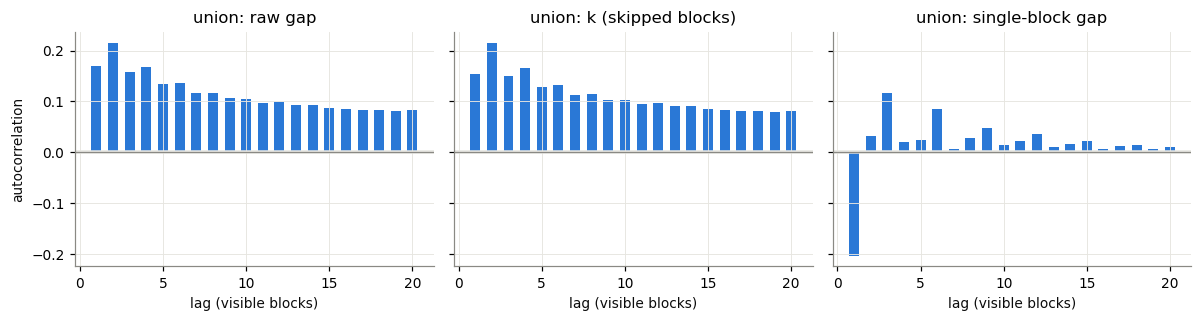

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
lags = np.arange(1, ACF_LAGS + 1)
for a, name in zip(ax, ["raw gap", "k (skipped blocks)", "single-block gap"]):
    a.bar(lags, acfs[name], width=0.6, color=C_CRYPTO)
    a.axhspan(-1.96 / np.sqrt(len(blk)), 1.96 / np.sqrt(len(blk)), color="#e6e5e0")
    a.axhline(0, color=C_MUTED, lw=0.8)
    a.set(title=f"union: {name}", xlabel="lag (visible blocks)")
ax[0].set_ylabel("autocorrelation")
plt.tight_layout(); plt.show()

## 5. Q3 — Does trading activity affect timing?
**H0:** next-gap distributions are equal after high- vs low-activity blocks (Mann–Whitney U).
Activity measures at block n (all backward-looking):
* `n_tr` — HL trades printed **in** block n (all 6 symbols),
* `hl_tr_1s` — HL trades in the 1 s up to and including block n,
* `bn_l1_1s` — Binance bookTicker updates (all 6 pairs) in the 1 s up to block n (Binance clock).

Two targets: **next raw gap** (visibility + clock) and **next gap, single-block only** (the clock). The second
conditions on the next gap being short — a descriptive test of the clock, not a usable forecast.
Also reported: the **contemporaneous** version (does a heavy block itself take longer?).

In [15]:
class Stream:
    """Sorted event times (ms) with O(log n) window counts / sums / as-of values. Windows are (a, b].
    Memory: counts use every event (`t`); the mid is stored only where it changes (`tm`, `lm`), which gives identical
    as-of values. `keep` marks those events, so `lmid_each` rebuilds the mid at every event."""
    def __init__(self, t, val=None, lmid=None):
        t = np.asarray(t)
        o = None if np.all(t[1:] >= t[:-1]) else np.argsort(t, kind="stable")
        self.t = t if o is None else t[o]
        self.cv = None if val is None else np.concatenate([[0.0], np.cumsum(np.asarray(val, float) if o is None else np.asarray(val, float)[o])])
        self.tm = self.lm = self.keep = None
        if lmid is not None:
            lm = np.asarray(lmid, float) if o is None else np.asarray(lmid, float)[o]
            self.keep = np.r_[True, lm[1:] != lm[:-1]]
            self.tm, self.lm = self.t[self.keep], lm[self.keep]
    def count(self, a, b):
        return np.searchsorted(self.t, b, "right") - np.searchsorted(self.t, a, "right")
    def sum(self, a, b):
        return self.cv[np.searchsorted(self.t, b, "right")] - self.cv[np.searchsorted(self.t, a, "right")]
    def lmid_at(self, q):
        i = np.searchsorted(self.tm, q, "right") - 1
        return np.where(i >= 0, self.lm[np.clip(i, 0, None)], np.nan)
    def lmid_each(self):
        return self.lm[np.cumsum(self.keep) - 1]
    def absret_bps(self, a, b):
        return np.abs(self.lmid_at(b) - self.lmid_at(a)) * 1e4
    def upto(self, cut):
        """The same stream with every event after `cut` removed (views, no copy). Used by the truncation tests."""
        s = object.__new__(Stream)
        k = np.searchsorted(self.t, cut, "right")
        s.t, s.cv = self.t[:k], None if self.cv is None else self.cv[:k + 1]
        s.keep = None if self.keep is None else self.keep[:k]
        km = 0 if self.tm is None else np.searchsorted(self.tm, cut, "right")
        s.tm, s.lm = (None, None) if self.tm is None else (self.tm[:km], self.lm[:km])
        return s

def make_streams(hl_l1, hl_tr, bn_l1, bn_tr):
    S = {"hl_tr": Stream(hl_tr.t.values, hl_tr.notional.values), "hl_l1": Stream(hl_l1.t.values)}
    for s in SYMS:
        b = PAIRS[s]
        r = bn_l1.attrs["rows"][b]   # contiguous block sorted by t, so the stream is a view (no copy)
        S[f"bn_l1:{s}"] = Stream(bn_l1.t.values[r], lmid=bn_l1.lmid.values[r])
        S[f"bn_tr:{s}"] = Stream(bn_tr.t[bn_tr.symbol == b].values)
        S[f"hl_tr:{s}"] = Stream(hl_tr.t[hl_tr.symbol == s].values)
        S[f"hl_l1:{s}"] = Stream(hl_l1.t[hl_l1.symbol == s].values, lmid=hl_l1.lmid[hl_l1.symbol == s].values)
    S["bn_tr"] = Stream(bn_tr.t[bn_tr.symbol.isin(PAIRS.values())].values)
    return S

STREAMS = make_streams(hl_l1, hl_tr, bn_l1, bn_tr)

In [16]:
def mw_compare(act, y, label, act_cut):
    hi, lo = y[act > act_cut], y[act <= act_cut]
    hi, lo = hi[~np.isnan(hi)], lo[~np.isnan(lo)]
    if len(hi) < 30 or len(lo) < 30:
        return {"test": label, "n_hi": len(hi), "n_lo": len(lo)}
    u = stats.mannwhitneyu(hi, lo, alternative="two-sided")
    rng = np.random.default_rng(SEED)
    bs = [np.median(rng.choice(hi, len(hi))) - np.median(rng.choice(lo, len(lo))) for _ in range(300)]
    return {"test": label, "n_hi": len(hi), "n_lo": len(lo), "median_hi": np.median(hi), "median_lo": np.median(lo),
            "diff ms": np.median(hi) - np.median(lo), "diff CI lo": np.percentile(bs, 2.5), "diff CI hi": np.percentile(bs, 97.5),
            "AUC P(hi>lo)": u.statistic / (len(hi) * len(lo)), "MW p": u.pvalue}

def q3_table(bt, label_prefix=""):
    t = bt.t.values.astype(float)
    acts = {"n_tr (in block)": bt.n_tr.values.astype(float),
            "hl_tr_1s": STREAMS["hl_tr"].count(t - 1000, t).astype(float),
            "bn_l1_1s": sum(STREAMS[f"bn_l1:{s}"].count(t - 1000, t) for s in SYMS).astype(float)}   # all 6 pairs
    nxt = bt.gap.shift(-1).values
    cur = bt.gap.values
    tr = bt.t.values <= T_SPLIT
    rows = []
    for an, a in acts.items():
        cut = np.quantile(a[tr], ACT_HIGH_Q)
        if cut == 0:   # e.g. most blocks have no trade: "high" = any trade
            cut = 0.0
        for yn, y in [("next gap (raw)", nxt), ("next gap (single-block only)", np.where(nxt <= SINGLE_MAX, nxt, np.nan)),
                      ("same-block gap (single-block only)", np.where(cur <= SINGLE_MAX, cur, np.nan))]:
            r = mw_compare(a, y, f"{label_prefix}{an} → {yn}", cut)
            r["hi cut"] = cut
            rows.append(r)
            log_trial(q="Q3", test=r["test"])
    return pd.DataFrame(rows).set_index("test")

q3_union = q3_table(blk)
q3_union

,n_hi,n_lo,median_hi,median_lo,diff ms,diff CI lo,diff CI hi,AUC P(hi>lo),MW p,hi cut
test,,,,,,,,,,
n_tr (in block) → next gap (raw),184476,1405632,74.0,76.0,-2.0,-2.0,-2.0,0.4769,4.7705e-229,1.0
n_tr (in block) → next gap (single-block only),118334,868449,67.0,67.0,0.0,0.0,0.0,0.4895,3.5215e-32,1.0
n_tr (in block) → same-block gap (single-block only),112344,874439,68.0,67.0,1.0,1.0,1.0,0.5242,1.5801e-154,1.0
hl_tr_1s → next gap (raw),303905,1286203,72.0,77.0,-5.0,-5.0,-5.0,0.4347,0.0000e+00,11.0
hl_tr_1s → next gap (single-block only),211683,775100,67.0,67.0,0.0,0.0,0.0,0.4917,6.9530e-32,11.0
hl_tr_1s → same-block gap (single-block only),214816,771967,67.0,67.0,0.0,0.0,0.0,0.4901,1.2349e-44,11.0
bn_l1_1s → next gap (raw),386595,1203513,72.0,78.0,-6.0,-6.0,-6.0,0.4189,0.0000e+00,772.0
bn_l1_1s → next gap (single-block only),273545,713238,67.0,67.0,0.0,0.0,0.0,0.4852,1.2057e-115,772.0
bn_l1_1s → same-block gap (single-block only),272315,714468,67.0,67.0,0.0,0.0,0.0,0.4859,1.0029e-104,772.0


In [17]:
rows = []
for s in SYMS:
    d = q3_table(inst[s], f"{s} | ")
    d["symbol"], d["group"] = s, GROUP[s]
    rows.append(d)
q3_inst = pd.concat(rows)
q3_inst[["n_hi", "n_lo", "median_hi", "median_lo", "diff ms", "diff CI lo", "diff CI hi", "AUC P(hi>lo)", "MW p"]]

,n_hi,n_lo,median_hi,median_lo,diff ms,diff CI lo,diff CI hi,AUC P(hi>lo),MW p
test,,,,,,,,,
BTC-USD-PERP | n_tr (in block) → next gap (raw),172170,864446,119.0,111.0,8.0,7.0,9.0,0.5212,5.3367e-170
BTC-USD-PERP | n_tr (in block) → next gap (single-block only),78142,414458,67.0,67.0,0.0,0.0,0.0,0.4993,5.1943e-01
BTC-USD-PERP | n_tr (in block) → same-block gap (single-block only),73368,419232,68.0,67.0,1.0,0.0,1.0,0.5089,1.0849e-14
BTC-USD-PERP | hl_tr_1s → next gap (raw),194194,842422,80.0,122.0,-42.0,-42.0,-42.0,0.3938,0.0000e+00
BTC-USD-PERP | hl_tr_1s → next gap (single-block only),115591,377009,67.0,67.0,0.0,0.0,0.0,0.4926,3.1748e-14
BTC-USD-PERP | hl_tr_1s → same-block gap (single-block only),117235,375365,67.0,67.0,0.0,0.0,0.0,0.4906,1.1952e-22
BTC-USD-PERP | bn_l1_1s → next gap (raw),250602,786014,77.0,129.0,-52.0,-52.0,-52.0,0.3473,0.0000e+00
BTC-USD-PERP | bn_l1_1s → next gap (single-block only),159206,333394,67.0,67.0,0.0,0.0,0.0,0.4839,3.6526e-75
BTC-USD-PERP | bn_l1_1s → same-block gap (single-block only),157204,335396,67.0,67.0,0.0,0.0,0.0,0.4841,4.9308e-73


## 6. Features + truncation test
One function builds every forecasting feature for a set of query blocks. Everything is a function of data with
time ≤ the query block's `t` (HL clock for HL, Binance clock for Binance). The truncation test recomputes features
with all data after a cut removed and checks that features at or before the cut are unchanged.

In [18]:
def build_features(bt, streams, sym=None):
    """Features at block n in exchange time (t_n). bt: block table (union or one instrument) with t, gap, n_tr, notional, n_l1."""
    t = bt.t.values.astype(float)
    tb = t
    g = bt.gap.values
    F = pd.DataFrame(index=bt.index)
    lg = np.log(pd.Series(g, index=bt.index))
    for j in range(10):
        F[f"lg{j}"] = lg.shift(j)                       # lg0 = log gap that ended at block n (known at t_n)
    gs = pd.Series(g, index=bt.index)
    F["med20"] = gs.rolling(20, min_periods=5).median()   # backward rolling, includes current gap only
    F["med200"] = gs.rolling(200, min_periods=20).median()
    F["single_share50"] = (gs <= SINGLE_MAX).astype(float).where(gs.notna()).rolling(50, min_periods=10).mean()
    # HL activity
    F["n_tr_blk"] = bt.n_tr.values
    F["lnot_blk"] = np.log1p(bt.notional.values)
    F["n_l1_blk"] = bt.n_l1.values
    if "n_sym" in bt:
        F["n_sym_blk"] = bt.n_sym.values
        F["upd_crypto_blk"] = bt.upd_crypto.values
        F["upd_tradfi_blk"] = bt.upd_tradfi.values
    F["hl_tr_1s"] = streams["hl_tr"].count(t - 1000, t)
    F["hl_lnot_1s"] = np.log1p(streams["hl_tr"].sum(t - 1000, t))
    F["hl_l1_1s"] = streams["hl_l1"].count(t - 1000, t)
    hl_cols = list(F.columns)
    # Binance activity (Binance clock; §8 replaces these with latency-aware versions)
    pairs = [sym] if sym else SYMS
    for w in (100, 1000):
        F[f"bn_l1_{w}"] = sum(streams[f"bn_l1:{s}"].count(tb - w, tb) for s in pairs)
        F[f"bn_tr_{w}"] = sum(streams[f"bn_tr:{s}"].count(tb - w, tb) for s in pairs)
        if sym:
            F[f"bn_absret_{w}"] = streams[f"bn_l1:{sym}"].absret_bps(tb - w, tb)
        else:
            for grp in ("crypto", "tradfi"):
                F[f"bn_absret_{w}_{grp}"] = np.nansum([streams[f"bn_l1:{s}"].absret_bps(tb - w, tb) for s in SYMS if GROUP[s] == grp], axis=0)
    bn_cols = [c for c in F.columns if c not in hl_cols]
    lag_cols = [c for c in hl_cols if c.startswith("lg") or c.startswith("med") or c.startswith("single")]
    return F, {"F1 lags": lag_cols, "F2 +HL activity": hl_cols, "F3 +Binance": hl_cols + bn_cols}

def truncation_test(bt, sym=None, n_cuts=3):
    full, _ = build_features(bt, STREAMS, sym)
    for frac in np.linspace(0.3, 0.8, n_cuts):
        cut = bt.t.quantile(frac)
        S_cut = {k: v.upto(cut) for k, v in STREAMS.items()}   # every event after the cut removed
        part, _ = build_features(bt[bt.t <= cut], S_cut, sym)
        a, b = full.loc[part.index].values, part.values
        ok = np.allclose(a, b, equal_nan=True)
        assert ok, f"LEAK: features at/before {cut} change when future data is removed ({np.argwhere(~np.isclose(a, b, equal_nan=True))[:5]})"
    return True

print("truncation test union:", truncation_test(blk))
print("truncation test BTC:", truncation_test(inst["BTC-USD-PERP"], "BTC-USD-PERP"))
print("truncation test xyz:TSLA:", truncation_test(inst["xyz:TSLA-USD-PERP"], "xyz:TSLA-USD-PERP"))

truncation test union: True


truncation test BTC: True


truncation test xyz:TSLA: True


## 7. Q4 — Can previous intervals predict the next? (Wald test)
OLS of log next gap on 10 lags of log gap (+ constant), Newey–West HAC. **H0:** all lag coefficients = 0.
Also: the same with HL activity added, testing whether activity adds anything given lags. Fit on train; OOS R² on test.

In [19]:
def q4(bt, sym=None, label="union"):
    F, sets = build_features(bt, STREAMS, sym)
    y = np.log(bt.gap.shift(-1))
    d = pd.concat([F, y.rename("y"), bt.t], axis=1).dropna()
    tr = d.t <= T_SPLIT
    out = {}
    lag_cols = [f"lg{j}" for j in range(10)]
    act_cols = ["n_tr_blk", "lnot_blk", "hl_tr_1s", "hl_l1_1s"]
    for nm, cols, test_cols in [("lags", lag_cols, lag_cols), ("lags+activity", lag_cols + act_cols, act_cols)]:
        X = sm.add_constant(d.loc[tr, cols])
        m = sm.OLS(d.loc[tr, "y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        R = np.zeros((len(test_cols), X.shape[1]))
        for i, c in enumerate(test_cols):
            R[i, list(X.columns).index(c)] = 1
        wt = m.wald_test(R, scalar=True)
        yhat = m.predict(sm.add_constant(d.loc[~tr, cols], has_constant="add"))
        yt = d.loc[~tr, "y"]
        r2_oos = 1 - np.sum((yt - yhat) ** 2) / np.sum((yt - d.loc[tr, "y"].mean()) ** 2)
        out[nm] = {"set": label, "model": nm, "tested": "lags" if nm == "lags" else "activity | lags",
                   "Wald F": float(wt.statistic), "Wald p": float(wt.pvalue), "R2 train": m.rsquared, "R2 OOS": r2_oos,
                   "coef lg0": m.params.get("lg0"), "n_train": int(tr.sum())}
        log_trial(q="Q4", set=label, model=nm)
    return list(out.values())

q4_tab = pd.DataFrame(q4(blk) + sum([q4(inst[s], s, s) for s in SYMS], [])).set_index(["set", "model"])
q4_tab

tested       Wald F       Wald p  R2 train  R2 OOS  coef lg0  n_train
set                model                                                                                        
union              lags                      lags   82797.1478   0.0000e+00    0.0971  0.1029    0.0427   953925
                   lags+activity  activity | lags   10552.6281   0.0000e+00    0.1080  0.1094    0.0166   953925
BTC-USD-PERP       lags                      lags  100805.0028   0.0000e+00    0.1422  0.1427    0.1346   613698
                   lags+activity  activity | lags    5029.1929   0.0000e+00    0.1501  0.1512    0.1140   613698
HYPE-USD-PERP      lags                      lags   65133.1247   0.0000e+00    0.1461  0.1191    0.2252   499347
                   lags+activity  activity | lags    3039.9276   0.0000e+00    0.1535  0.1267    0.2066   499347
AAVE-USD-PERP      lags                      lags   26525.4144   0.0000e+00    0.0958  0.1055    0.2058   277864
                   lags+activity  activity | lags    2399.3738   0.0000e+00    0.1034  0.1149    0.1829   277864
xyz:SP500-USD-PERP lags                      lags   51961.4158   0.0000e+00    0.2301  0.2888    0.2627   159981
                   lags+activity  activity | lags    1832.3825   0.0000e+00    0.2474  0.3018    0.2284   159981
xyz:TSLA-USD-PERP  lags                      lags   40183.0498   0.0000e+00    0.2270  0.2338    0.2747   135135
                   lags+activity  activity | lags     936.2381  2.3430e-201    0.2336  0.2410    0.2544   135135
xyz:CL-USD-PERP    lags                      lags   44458.4774   0.0000e+00    0.2260  0.2652    0.2874   181180
                   lags+activity  activity | lags     731.0477  6.5935e-157    0.2296  0.2703    0.2766   181180

## 8. Q5 — Can we forecast the next block within an interval? (out-of-sample, with latency)
The target is still **exchange block time**. The forecast is made at the moment we *know* block n:
`q_n = t_n + latency` (made monotone, so we never act on block n before every earlier block is known).
* **Target** y_n = (exchange time of the first visible block after q_n) − q_n. With ~0 latency this is the next gap;
  with real latency it's the residual wait from the moment we find out.
* **HL features** = the §6 exchange-time features of block n (all built from blocks ≤ n, so all known at q_n),
  plus `staleness` = q_n − t_n.
* **Binance features** use Binance's own latency: only Binance events with `t + latency ≤ q_n` count.

Nested sets, quantile gradient boosting (q10/q50/q90), fit on train and scored on test:
**F0** unconditional train quantiles → **F1** gap lags + staleness → **F2** + HL activity → **F3** + Binance.
Metrics: pinball skill vs F0 (95% block-bootstrap CI), gain over the previous set, 80% coverage, width, MAE of the median.

In [20]:
def latency_view(scen, seed=SEED):
    """Known times under a latency scenario: per union block (prefix-max) + Binance streams keyed on known time."""
    rng = np.random.default_rng(seed)
    t = blk.t.values.astype(float)
    if scen["kind"] == "normal":
        mu, sd = scen["hl"]
        known = t + np.clip(rng.normal(mu, sd, len(t)), 0, None)
        bn_known_l1, bn_known_tr = bn_l1.t.values, bn_tr.t.values   # bn=None: Binance known at its exchange time
    else:
        known = blk_recv.loc[blk.t].values
        bn_known_l1, bn_known_tr = bn_l1.recv.values, bn_tr.recv.values
    K = pd.Series(np.maximum.accumulate(known), index=blk.t.values)   # block n usable only once blocks <= n are all known
    S = {}
    for s in SYMS:
        m1, m2 = bn_l1.attrs["rows"][PAIRS[s]], (bn_tr.symbol == PAIRS[s]).values
        S[f"bn_l1:{s}"] = Stream(bn_known_l1[m1], lmid=bn_l1.lmid.values[m1])
        S[f"bn_tr:{s}"] = Stream(bn_known_tr[m2])
    return K, S

def lat_features(bt, sym, K, S_bn):
    F, sets = build_features(bt, STREAMS, sym)
    bn_cols = [c for c in sets["F3 +Binance"] if c not in sets["F2 +HL activity"]]
    q = K.loc[bt.t.values].values
    F["staleness"] = q - bt.t.values
    pairs = [sym] if sym else SYMS
    for w in (100, 1000):    # recompute Binance features on known time at q (replaces the exchange-time versions)
        F[f"bn_l1_{w}"] = sum(S_bn[f"bn_l1:{s}"].count(q - w, q) for s in pairs)
        F[f"bn_tr_{w}"] = sum(S_bn[f"bn_tr:{s}"].count(q - w, q) for s in pairs)
        if sym:
            F[f"bn_absret_{w}"] = S_bn[f"bn_l1:{sym}"].absret_bps(q - w, q)
        else:
            for grp in ("crypto", "tradfi"):
                F[f"bn_absret_{w}_{grp}"] = np.nansum([S_bn[f"bn_l1:{s}"].absret_bps(q - w, q) for s in SYMS if GROUP[s] == grp], axis=0)
    sets = {"F1 lags": sets["F1 lags"] + ["staleness"], "F2 +HL activity": sets["F2 +HL activity"] + ["staleness"],
            "F3 +Binance": sets["F2 +HL activity"] + ["staleness"] + bn_cols}
    # target: first visible block of this table strictly after q, in exchange time, same connection
    tt = bt.t.values
    j = np.searchsorted(tt, q, "right")
    ok = j < len(tt)
    jj = np.clip(j, 0, len(tt) - 1)
    ok &= bt.ordinal.values[jj] == bt.ordinal.values
    y = np.where(ok, tt[jj] - q, np.nan)
    return F, sets, pd.Series(y, index=bt.index), q

def lat_truncation_test(scen_name, sym=None):
    """Binance known-time features at q must not change when every event known after a cut is deleted."""
    K, S_full = latency_view(LATENCY_SCENARIOS[scen_name])
    bt = blk if sym is None else inst[sym]
    F_full, _, _, q = lat_features(bt, sym, K, S_full)
    for frac in (0.4, 0.7):
        cut = np.quantile(q, frac)
        S_cut = {k: v.upto(cut) for k, v in S_full.items()}
        F_cut, _, _, _ = lat_features(bt, sym, K, S_cut)
        keep = q <= cut
        a, b = F_full.loc[keep].values, F_cut.loc[keep].values
        assert np.allclose(a, b, equal_nan=True), f"LEAK in latency features ({scen_name}, {sym})"
        assert (K.loc[bt.t.values[keep]].values <= cut).all()
    return True

for nm in LATENCY_SCENARIOS:
    print(f"latency truncation test [{nm}] union:", lat_truncation_test(nm), "| HYPE:", lat_truncation_test(nm, "HYPE-USD-PERP"))

latency truncation test [N(0.50, 0.05) ms] union: True | HYPE: True


latency truncation test [measured ts_recv] union: True | HYPE: True


In [21]:
def pinball(y, q, tau):
    d = y - q
    return np.maximum(tau * d, (tau - 1) * d)

def block_boot_ci(diff, reps=BOOT_REPS, block=BOOT_BLOCK, seed=SEED):
    n = len(diff); rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block)); starts = rng.integers(0, max(n - block, 1), size=(reps, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(reps, -1)[:, :n]
    m = diff[idx].mean(1)
    return np.percentile(m, [2.5, 97.5])

def q5(bt, sym, label, scen_name, K, S_bn):
    F, sets, y, q = lat_features(bt, sym, K, S_bn)
    d = pd.concat([F, y.rename("y"), bt.t], axis=1)
    d = d[d.y.notna() & d.lg0.notna()]
    tr = (d.t <= T_SPLIT).values
    ytr, yte = d.y.values[tr], d.y.values[~tr]
    preds = {"F0 unconditional": np.tile(np.quantile(ytr, QUANTILES), (len(yte), 1))}
    for nm, cols in sets.items():
        P = []
        for tau in QUANTILES:
            m = HistGradientBoostingRegressor(loss="quantile", quantile=tau, **HGB_KW).fit(d.loc[tr, cols], ytr)
            P.append(m.predict(d.loc[~tr, cols]))
        preds[nm] = np.sort(np.column_stack(P), axis=1)   # no quantile crossing
        log_trial(q="Q5", set=label, model=nm, latency=scen_name)
    loss = {k: np.mean([pinball(yte, p[:, i], tau) for i, tau in enumerate(QUANTILES)], axis=0) for k, p in preds.items()}
    rows, names = [], list(preds)
    ref = loss["F0 unconditional"]
    for i, k in enumerate(names):
        p = preds[k]
        prev = loss[names[i - 1]] if i > 0 else None
        ci0 = block_boot_ci((ref - loss[k]) / ref.mean()) if i > 0 else (np.nan, np.nan)
        cip = block_boot_ci((prev - loss[k]) / ref.mean()) if i > 1 else (np.nan, np.nan)
        rows.append({"latency": scen_name, "set": label, "features": k, "group": GROUP.get(sym, "all"), "n_test": len(yte),
                     "median staleness ms": np.median(F.staleness.loc[d.index[~tr]]), "median target ms": np.median(yte),
                     "pinball": loss[k].mean(), "skill vs F0": 1 - loss[k].mean() / ref.mean(),
                     "skill CI lo": ci0[0], "skill CI hi": ci0[1],
                     "gain vs prev set": (prev.mean() - loss[k].mean()) / ref.mean() if prev is not None else np.nan,
                     "gain CI lo": cip[0], "gain CI hi": cip[1],
                     "coverage 80%": np.mean((yte >= p[:, 0]) & (yte <= p[:, 2])),
                     "median width ms": np.median(p[:, 2] - p[:, 0]), "MAE median ms": np.mean(np.abs(yte - p[:, 1]))})
    return pd.DataFrame(rows)

q5_rows = []
for scen_name, scen in LATENCY_SCENARIOS.items():
    K, S_bn = latency_view(scen)
    for s in [None] + SYMS:
        q5_rows.append(q5(blk if s is None else inst[s], s, s or "union", scen_name, K, S_bn))
q5_all = pd.concat(q5_rows)
del K, S_bn, bn_l1   # free memory: nothing below needs the raw Binance quotes (STREAMS keeps what it needs)
q5_all.set_index(["latency", "set", "features"])[["n_test", "median staleness ms", "median target ms", "skill vs F0",
    "skill CI lo", "skill CI hi", "gain vs prev set", "gain CI lo", "gain CI hi", "coverage 80%", "median width ms", "MAE median ms"]]

C:\Users\markp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\markp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

n_test  median staleness ms  median target ms  skill vs F0  skill CI lo  skill CI hi  gain vs prev set  gain CI lo  gain CI hi  coverage 80%  \
latency          set                features                                                                                                                                                         
N(0.50, 0.05) ms union              F0 unconditional  636035               0.5000           72.5779       0.0000          NaN          NaN               NaN         NaN         NaN        0.8215   
                                    F1 lags           636035               0.5000           72.5779       0.1735       0.1710       0.1756            0.1735         NaN         NaN        0.7990   
                                    F2 +HL activity   636035               0.5000           72.5779       0.1855       0.1828       0.1877            0.0119      0.0114      0.0125        0.7976   
                                    F3 +Binance       636035               0.5000           72.5779       0.1945       0.1917       0.1970            0.0090      0.0084      0.0097        0.7957   
                 BTC-USD-PERP       F0 unconditional  422770               0.4998           99.4785       0.0000          NaN          NaN               NaN         NaN         NaN        0.8062   
                                    F1 lags           422770               0.4998           99.4785       0.1356       0.1310       0.1413            0.1356         NaN         NaN        0.7910   
                                    F2 +HL activity   422770               0.4998           99.4785       0.1421       0.1375       0.1478            0.0066      0.0060      0.0071        0.7983   
                                    F3 +Binance       422770               0.4998           99.4785       0.1629       0.1583       0.1690            0.0208      0.0199      0.0218        0.7979   
                 HYPE-USD-PERP      F0 unconditional  345617               0.5000          117.4844       0.0000          NaN          NaN               NaN         NaN         NaN        0.8043   
                                    F1 lags           345617               0.5000          117.4844       0.1125       0.1063       0.1188            0.1125         NaN         NaN        0.7919   
                                    F2 +HL activity   345617               0.5000          117.4844       0.1216       0.1152       0.1284            0.0091      0.0081      0.0101        0.7988   
                                    F3 +Binance       345617               0.5000          117.4844       0.1627       0.1553       0.1704            0.0411      0.0393      0.0430        0.7971   
                 AAVE-USD-PERP      F0 unconditional  222208               0.5002          135.5509       0.0000          NaN          NaN               NaN         NaN         NaN        0.8199   
                                    F1 lags           222208               0.5002          135.5509       0.1028       0.0949       0.1117            0.1028         NaN         NaN        0.7969   
                                    F2 +HL activity   222208               0.5002          135.5509       0.1050       0.0975       0.1138            0.0022      0.0016      0.0029        0.7990   
                                    F3 +Binance       222208               0.5002          135.5509       0.1712       0.1634       0.1818            0.0662      0.0632      0.0696        0.7984   
                 xyz:SP500-USD-PERP F0 unconditional  183720               0.5000          142.6030       0.0000          NaN          NaN               NaN         NaN         NaN        0.8203   
                                    F1 lags           183720               0.5000          142.6030       0.2311       0.2185       0.2430            0.2311         NaN         NaN        0.7876   
                                    F2 +HL activity   183720               0.5000          142

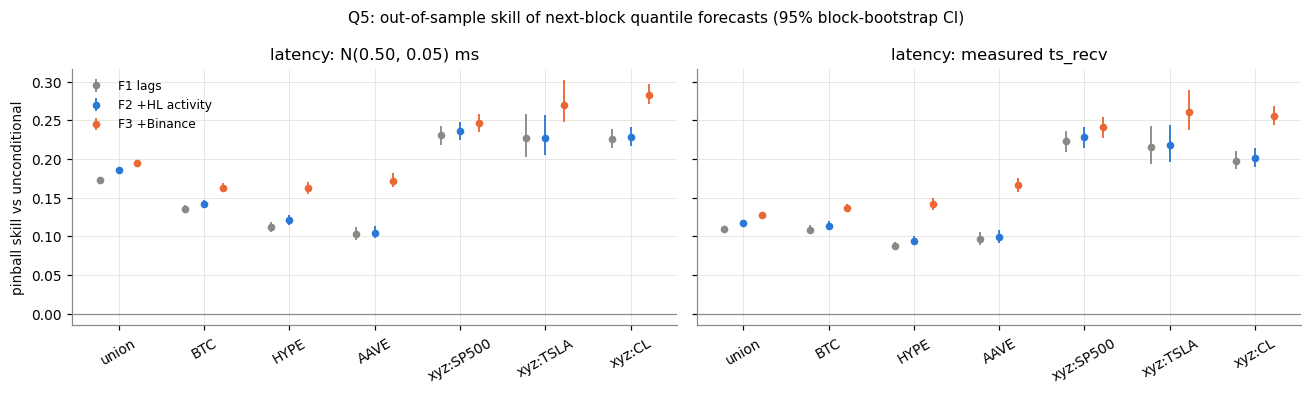

In [22]:
fig, axes = plt.subplots(1, len(LATENCY_SCENARIOS), figsize=(12, 3.6), sharey=True)
sets_order = ["F1 lags", "F2 +HL activity", "F3 +Binance"]
labels = ["union"] + SYMS
xs = np.arange(len(labels))
for ax, scen_name in zip(np.atleast_1d(axes), LATENCY_SCENARIOS):
    for j, fs in enumerate(sets_order):
        sub = q5_all[(q5_all.features == fs) & (q5_all.latency == scen_name)].set_index("set").loc[labels]
        err = np.vstack([sub["skill vs F0"] - sub["skill CI lo"], sub["skill CI hi"] - sub["skill vs F0"]])
        ax.errorbar(xs + (j - 1) * 0.22, sub["skill vs F0"], yerr=err, fmt="o", ms=4, lw=1.2,
                    color=[C_MUTED, C_CRYPTO, C_TRADFI][j], label=fs, capsize=0)
    ax.axhline(0, color=C_MUTED, lw=0.8)
    ax.set_xticks(xs, [l.replace("-USD-PERP", "") for l in labels], rotation=30)
    ax.set(title=f"latency: {scen_name}")
np.atleast_1d(axes)[0].set_ylabel("pinball skill vs unconditional")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.suptitle("Q5: out-of-sample skill of next-block quantile forecasts (95% block-bootstrap CI)", fontsize=10)
plt.tight_layout(); plt.show()

## 9. Binance inside HL's gaps
### 9.1 Timing: does Binance activity *during* the gap move the hazard of the next HL block?
Discrete-time hazard: for every gap, checkpoints at t = 0, 10, …, < min(gap, 600) ms after block n. Event = the next
visible block lands in (t, t+10]. Model A uses only info at block n + elapsed t; model B adds Binance activity since
block n and in the last 20 ms (Binance clock). Scored by test log-loss; ΔLL CI by block bootstrap over gaps.

In [23]:
def hazard_frame(bt, sym=None):
    F, _ = build_features(bt, STREAMS, sym)
    base_cols = ["lg0", "lg1", "med20", "med200", "n_tr_blk", "hl_tr_1s", "hl_l1_1s"] + (["n_sym_blk"] if sym is None else [])
    G = bt.gap.shift(-1).values
    ok = ~np.isnan(G) & F.lg0.notna().values
    t0, G, Fb = bt.t.values[ok].astype(float), G[ok], F.loc[ok, base_cols].values
    nstep = np.minimum(np.ceil(G / HAZ_STEP), HAZ_TMAX // HAZ_STEP).astype(int)
    gi = np.repeat(np.arange(len(G)), nstep)
    el = np.concatenate([np.arange(n) * HAZ_STEP for n in nstep]).astype(float)
    ev_ = (G[gi] > el) & (G[gi] <= el + HAZ_STEP)
    q = t0[gi] + el
    qb, t0b = q, t0[gi]
    pairs = [sym] if sym else SYMS
    X = pd.DataFrame(Fb[gi], columns=base_cols)
    X["elapsed"] = el
    A_cols = list(X.columns)
    X["bn_l1_since"] = sum(STREAMS[f"bn_l1:{s}"].count(t0b, qb) for s in pairs)
    X["bn_l1_last20"] = sum(STREAMS[f"bn_l1:{s}"].count(qb - 20, qb) for s in pairs)
    X["bn_tr_since"] = sum(STREAMS[f"bn_tr:{s}"].count(t0b, qb) for s in pairs)
    X["bn_absret_since"] = np.nansum([STREAMS[f"bn_l1:{s}"].absret_bps(t0b, qb) for s in pairs], axis=0)
    return X, ev_.astype(int), gi, t0[gi], A_cols

def hazard_eval(bt, sym=None, label="union"):
    X, yv, gi, tq, A_cols = hazard_frame(bt, sym)
    tr = tq <= T_SPLIT
    out = {}
    for nm, cols in [("A: HL info + elapsed", A_cols), ("B: + Binance in gap", list(X.columns))]:
        m = HistGradientBoostingClassifier(**HGB_KW).fit(X.loc[tr, cols], yv[tr])
        p = np.clip(m.predict_proba(X.loc[~tr, cols])[:, 1], 1e-6, 1 - 1e-6)
        out[nm] = -(yv[~tr] * np.log(p) + (1 - yv[~tr]) * np.log(1 - p))
        log_trial(q="Q-hazard", set=label, model=nm)
    d = out["A: HL info + elapsed"] - out["B: + Binance in gap"]
    per_gap = pd.Series(d).groupby(gi[~tr]).sum().values     # bootstrap over gaps, in time order
    ci = block_boot_ci(per_gap) / (len(d) / len(per_gap))
    return {"set": label, "group": GROUP.get(sym, "all"), "rows_test": len(d),
            "LL A": out["A: HL info + elapsed"].mean(), "LL B": out["B: + Binance in gap"].mean(),
            "ΔLL (A−B) per row": d.mean(), "CI lo": ci[0], "CI hi": ci[1],
            "rel. improvement": d.mean() / out["A: HL info + elapsed"].mean()}

haz = pd.DataFrame([hazard_eval(blk if s is None else inst[s], s, s or "union")
                    for s in [None] + SYMS]).set_index("set")
haz

,group,rows_test,LL A,LL B,ΔLL (A−B) per row,CI lo,CI hi,rel. improvement
set,,,,,,,,
union,all,6497143,0.1884,0.1887,-3.4916e-04,-3.8018e-04,-3.1434e-04,-1.8537e-03
BTC-USD-PERP,crypto,6139582,0.1777,0.1774,2.6367e-04,2.1106e-04,3.1894e-04,1.4838e-03
HYPE-USD-PERP,crypto,5598502,0.1670,0.1665,5.1331e-04,4.8199e-04,5.5423e-04,3.0740e-03
AAVE-USD-PERP,crypto,4774545,0.1431,0.1417,1.4898e-03,1.4246e-03,1.5515e-03,1.0407e-02
xyz:SP500-USD-PERP,tradfi,4264425,0.1308,0.1308,7.9808e-06,-2.0061e-05,3.8565e-05,6.1000e-05
xyz:TSLA-USD-PERP,tradfi,3531200,0.1331,0.1317,1.4545e-03,1.3716e-03,1.5524e-03,1.0924e-02
xyz:CL-USD-PERP,tradfi,4515333,0.1475,0.1463,1.1646e-03,1.0983e-03,1.2201e-03,7.8965e-03


### 9.2 Clock vs visibility
A Binance gain in 9.1 can come from two very different things:
* **visibility** — Binance moves → HL quotes on that instrument reprice → the next block becomes *visible* sooner,
* **clock** — Binance activity actually changes how long HL takes to commit a block.

Clock test: among next gaps that are single-block, is gap length related to Binance activity in the first 40 ms
after block n (before the earliest plausible block end)? Spearman ρ with bootstrap CI. Descriptive (conditions on the
next gap being short).

In [24]:
rows = []
for s_ in [None] + SYMS:
    bt = blk if s_ is None else inst[s_]
    G = bt.gap.shift(-1).values; t = bt.t.values.astype(float)
    m = (G <= SINGLE_MAX) & ~np.isnan(G)
    pairs = [s_] if s_ else SYMS
    x = sum(STREAMS[f"bn_l1:{s}"].count(t[m], t[m] + 40) for s in pairs).astype(float)
    r = stats.spearmanr(x, G[m])
    rng = np.random.default_rng(SEED)
    bs = [stats.spearmanr(x[i], G[m][i]).statistic for i in (rng.integers(0, m.sum(), m.sum()) for _ in range(200))]
    rows.append({"set": s_ or "union", "group": GROUP.get(s_, "all"), "n single-block next gaps": int(m.sum()),
                 "spearman(bn updates in first 40ms, gap)": r.statistic, "CI lo": np.percentile(bs, 2.5),
                 "CI hi": np.percentile(bs, 97.5), "p": r.pvalue})
clock_test = pd.DataFrame(rows).set_index("set")
clock_test

,group,n single-block next gaps,"spearman(bn updates in first 40ms, gap)",CI lo,CI hi,p
set,,,,,,
union,all,986783,-0.0046,-0.0067,-0.0027,5.2442e-06
BTC-USD-PERP,crypto,492600,-0.0059,-0.0086,-0.0031,3.1849e-05
HYPE-USD-PERP,crypto,376610,0.0038,0.0002,0.0071,2.0278e-02
AAVE-USD-PERP,crypto,160107,0.0028,-0.0023,0.0074,2.5861e-01
xyz:SP500-USD-PERP,tradfi,93647,-0.0020,-0.0067,0.0042,5.4427e-01
xyz:TSLA-USD-PERP,tradfi,92065,-0.0022,-0.0097,0.0045,5.0763e-01
xyz:CL-USD-PERP,tradfi,143501,-0.0072,-0.0124,-0.0015,6.7270e-03


### 9.3 Price: does Binance inside the gap tell you HL's next move?
For each instrument, consecutive HL l1 updates a → b. ΔHL = HL log-mid change (bps).
* **Lead profile:** corr(ΔHL, Binance return over (t_a+s, t_b+s]) across shifts s. A peak at s < 0 means Binance
  moves before HL; the location also absorbs any clock offset.
* **Within-gap predictive:** Binance return over (t_a, t_b − δ] (known before block b lands, if gap > δ) → ΔHL.
  OLS slope fit on train, OOS R² on test vs a zero forecast, and sign hit-rate where both are non-zero.

In [25]:
lead_prof, lead_rows = {}, []
for s in SYMS:
    h = hl_l1[hl_l1.symbol == s].sort_values("t").drop_duplicates("t", keep="last")
    h = h[h.conn_ordinal == h.conn_ordinal.shift()]   # pairs within one connection
    ta = h.t.shift().values; tb = h.t.values.astype(float); dhl = (h.lmid.diff().values) * 1e4
    ok = ~np.isnan(ta) & ~np.isnan(dhl)
    ta, tb, dhl = ta[ok], tb[ok], dhl[ok]
    bn = STREAMS[f"bn_l1:{s}"]
    prof = []
    for sh in LEAD_SHIFTS:
        r = (bn.lmid_at(tb + sh) - bn.lmid_at(ta + sh)) * 1e4
        v = ~np.isnan(r)
        prof.append(np.corrcoef(dhl[v], r[v])[0, 1])
    lead_prof[s] = np.array(prof)
    tr = tb <= T_SPLIT
    for dl in WITHIN_DELTAS:
        r = (bn.lmid_at(tb - dl) - bn.lmid_at(ta)) * 1e4
        v = ~np.isnan(r) & ((tb - ta) > dl)
        b = np.sum(r[v & tr] * dhl[v & tr]) / np.sum(r[v & tr] ** 2)   # no-intercept OLS slope (train)
        te = v & ~tr
        r2 = 1 - np.sum((dhl[te] - b * r[te]) ** 2) / np.sum(dhl[te] ** 2)
        nz = te & (dhl != 0) & (r != 0)
        lead_rows.append({"symbol": s, "group": GROUP[s], "delta ms": dl, "n_test": int(te.sum()),
                          "share HL mid moved": np.mean(dhl[te] != 0), "slope (train)": b, "OOS R2": r2,
                          "sign hit-rate": np.mean(np.sign(dhl[nz]) == np.sign(r[nz])), "n sign": int(nz.sum())})
        log_trial(q="Q-lead", set=s, model=f"within-gap delta={dl}")
lead_tab = pd.DataFrame(lead_rows).set_index(["symbol", "delta ms"])
peak = pd.DataFrame({s: {"peak shift ms": LEAD_SHIFTS[np.nanargmax(p)], "peak corr": np.nanmax(p), "corr at 0": p[LEAD_SHIFTS == 0][0]}
                     for s, p in lead_prof.items()}).T
display(peak)
lead_tab

,peak shift ms,peak corr,corr at 0
BTC-USD-PERP,-490.0,0.3024,0.0645
HYPE-USD-PERP,-230.0,0.2231,0.1713
AAVE-USD-PERP,-180.0,0.4081,0.2801
xyz:SP500-USD-PERP,-200.0,0.3070,0.2607
xyz:TSLA-USD-PERP,220.0,0.4070,0.3809
xyz:CL-USD-PERP,-200.0,0.3772,0.1806


group  n_test  share HL mid moved  slope (train)  OOS R2  sign hit-rate  n sign
symbol             delta ms                                                                                  
BTC-USD-PERP       10        crypto  422306              0.0618         0.0237  0.0056         0.8188    2456
                   30        crypto  422281              0.0618         0.0263  0.0061         0.8300    2012
                   60        crypto  391364              0.0586         0.0275  0.0016         0.8537    1237
HYPE-USD-PERP      10        crypto  345267              0.3434         0.1195  0.0399         0.7518   15234
                   30        crypto  345255              0.3433         0.1321  0.0435         0.7644   13011
                   60        crypto  322162              0.3374         0.1639  0.0536         0.7975    9093
AAVE-USD-PERP      10        crypto  222146              0.4581         0.1988  0.1003         0.8002   20609
                   30        crypto  222128              0.4581         0.2120  0.1055         0.8146   18859
                   60        crypto  209629              0.4563         0.2345  0.1213         0.8497   15759
xyz:SP500-USD-PERP 10        tradfi  183542              0.2968         0.0684  0.0458         0.8754    2191
                   30        tradfi  183530              0.2968         0.0716  0.0476         0.8881    1957
                   60        tradfi  174977              0.2938         0.0757  0.0515         0.9113    1544
xyz:TSLA-USD-PERP  10        tradfi  157435              0.5487         0.1089  0.0964         0.7612   18908
                   30        tradfi  157420              0.5487         0.1318  0.1147         0.7796   17309
                   60        tradfi  148957              0.5495         0.1799  0.1560         0.8207   14559
xyz:CL-USD-PERP    10        tradfi  233664              0.6108         0.1322  0.0385         0.7717   12876
                   30        tradfi  233652              0.6108         0.1436  0.0418         0.7948   11521
                   60        tradfi  221990              0.6098         0.1743  0.0506         0.8395    9270

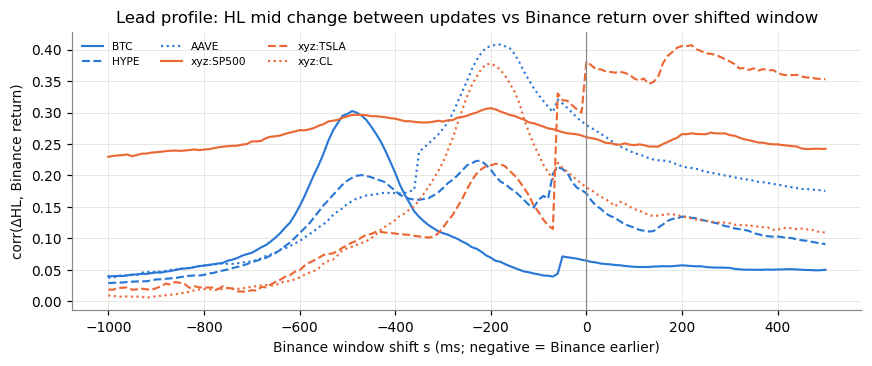

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for s in SYMS:
    ax.plot(LEAD_SHIFTS, lead_prof[s], color=C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI, lw=1.4,
            ls="-" if s in ("BTC-USD-PERP", "xyz:SP500-USD-PERP") else ("--" if s in ("HYPE-USD-PERP", "xyz:TSLA-USD-PERP") else ":"),
            label=s.replace("-USD-PERP", ""))
ax.axvline(0, color=C_MUTED, lw=0.8)
ax.set(xlabel="Binance window shift s (ms; negative = Binance earlier)", ylabel="corr(ΔHL, Binance return)",
       title="Lead profile: HL mid change between updates vs Binance return over shifted window")
ax.legend(frameon=False, fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

### 9.4 What does the Binance lead look like? (event study)
The lead profile in 9.3 is one correlation per shift. This makes it visible. A Binance **jump** is a Binance mid
move over the previous 50 ms whose size is in the top 0.5% for that pair; jumps are kept ≥ 2 s apart. Around each
jump time τ (Binance clock), both mids are sampled every 10 ms. Each path is signed by the jump direction and
measured in bps from its own value 1 s before τ. Lines are the mean across jumps.
If HL follows Binance, the HL line rises *after* the Binance line. `t50` is when a line first reaches half of
its level at +2 s, and the lag is HL t50 − Binance t50.
Caveats: HL can only step at its own blocks/updates, and any HL↔Binance clock offset slides the HL line sideways.

In [27]:
def jump_events(s):
    b = STREAMS[f"bn_l1:{s}"]
    lme, r, CH = b.lmid_each(), np.empty(len(b.t)), 10_000_000   # in chunks: BTC has >100M updates
    for i in range(0, len(b.t), CH):
        r[i:i + CH] = (lme[i:i + CH] - b.lmid_at(b.t[i:i + CH].astype(float) - EVT_RET_MS)) * 1e4
    del lme
    t = b.t
    cut = np.nanquantile(np.abs(r), EVT_Q)
    cand = np.where(np.abs(r) >= cut)[0]
    keep, last = [], -np.inf
    for i in cand:                       # first qualifying update, then nothing for EVT_MIN_SEP
        if t[i] - last >= EVT_MIN_SEP:
            keep.append(i); last = t[i]
    keep = np.array(keep, int)
    return t[keep].astype(float), np.sign(r[keep]), cut

def t50(path):
    final = path[-1]
    idx = np.where((EVT_WIN >= -200) & (path >= 0.5 * final))[0]
    return EVT_WIN[idx[0]] if len(idx) and final > 0 else np.nan

evt, evt_rows = {}, []
for s in SYMS:
    tau, sg, cut = jump_events(s)
    hl, bn = STREAMS[f"hl_l1:{s}"], STREAMS[f"bn_l1:{s}"]
    G = tau[:, None] + EVT_WIN[None, :]
    pb = (bn.lmid_at(G) - bn.lmid_at(tau - 1000)[:, None]) * 1e4 * sg[:, None]
    ph = (hl.lmid_at(G) - hl.lmid_at(tau - 1000)[:, None]) * 1e4 * sg[:, None]
    ok = ~np.isnan(pb).any(1) & ~np.isnan(ph).any(1) & (tau - 1000 > hl.t[0])
    ok &= same_segment(tau - 1000, tau + EVT_WIN[-1])   # the whole window inside one HL segment (no hole/reconnect)
    evt[s] = {"bn": pb[ok].mean(0), "hl": ph[ok].mean(0), "tau": tau[ok], "sign": sg[ok]}
    b50, h50 = t50(evt[s]["bn"]), t50(evt[s]["hl"])
    evt_rows.append({"symbol": s, "group": GROUP[s], "n jumps": int(ok.sum()), "jump cut bps (50ms)": cut,
                     "Binance move @+2s bps": evt[s]["bn"][-1], "HL move @+2s bps": evt[s]["hl"][-1],
                     "HL/Binance @+2s": evt[s]["hl"][-1] / evt[s]["bn"][-1],
                     "Binance t50 ms": b50, "HL t50 ms": h50, "lag (HL−Binance) ms": h50 - b50})
evt_tab = pd.DataFrame(evt_rows).set_index("symbol")
evt_tab

,group,n jumps,jump cut bps (50ms),Binance move @+2s bps,HL move @+2s bps,HL/Binance @+2s,Binance t50 ms,HL t50 ms,lag (HL−Binance) ms
symbol,,,,,,,,,
BTC-USD-PERP,crypto,751,1.7973,2.6567,2.3581,0.8876,0,540,540
HYPE-USD-PERP,crypto,533,4.0471,4.8321,4.7384,0.9806,0,290,290
AAVE-USD-PERP,crypto,394,4.0630,5.4160,5.6013,1.0342,0,350,350
xyz:SP500-USD-PERP,tradfi,218,1.0499,1.6438,1.3342,0.8116,0,610,610
xyz:TSLA-USD-PERP,tradfi,188,5.5598,6.1495,6.0325,0.9810,0,370,370
xyz:CL-USD-PERP,tradfi,192,4.1104,5.2192,5.2143,0.9991,0,450,450


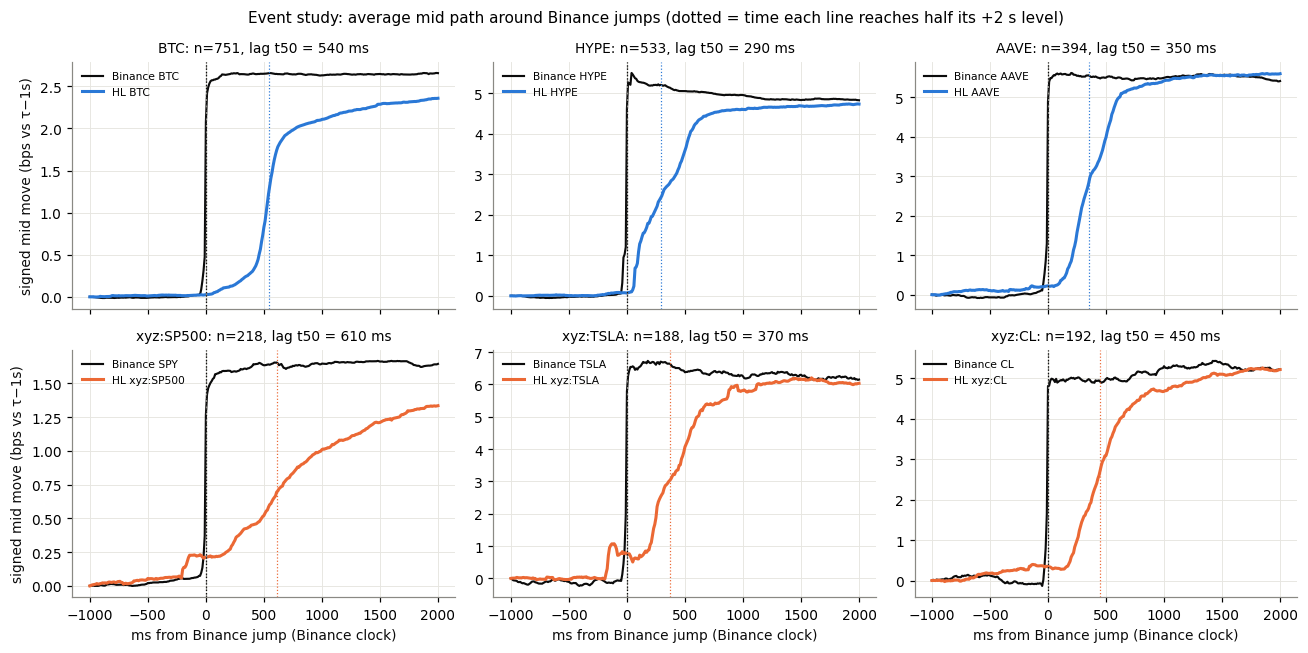

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, s in zip(axes.ravel(), SYMS):
    col = C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI
    ax.plot(EVT_WIN, evt[s]["bn"], color=C_INK, lw=1.4, label=f"Binance {PAIRS[s].replace('-USDT-PERP', '')}")
    ax.plot(EVT_WIN, evt[s]["hl"], color=col, lw=2, label=f"HL {s.replace('-USD-PERP', '')}")
    ax.axvline(0, color=C_MUTED, lw=0.8, ls="--")
    r = evt_tab.loc[s]
    for v, c in [(r["Binance t50 ms"], C_INK), (r["HL t50 ms"], col)]:
        if np.isfinite(v):
            ax.axvline(v, color=c, lw=0.8, ls=":")
    ax.set_title(f"{s.replace('-USD-PERP', '')}: n={int(r['n jumps'])}, lag t50 = {r['lag (HL−Binance) ms']:.0f} ms", fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("ms from Binance jump (Binance clock)")
for ax in axes[:, 0]:
    ax.set_ylabel("signed mid move (bps vs τ−1s)")
fig.suptitle("Event study: average mid path around Binance jumps (dotted = time each line reaches half its +2 s level)", fontsize=10)
plt.tight_layout(); plt.show()

**One raw example: the largest BTC jump.** Step lines are the actual quote updates, not averages. The ticks at the
bottom are HL visible blocks (any of the 6 instruments), so you can see where HL *could* have updated.

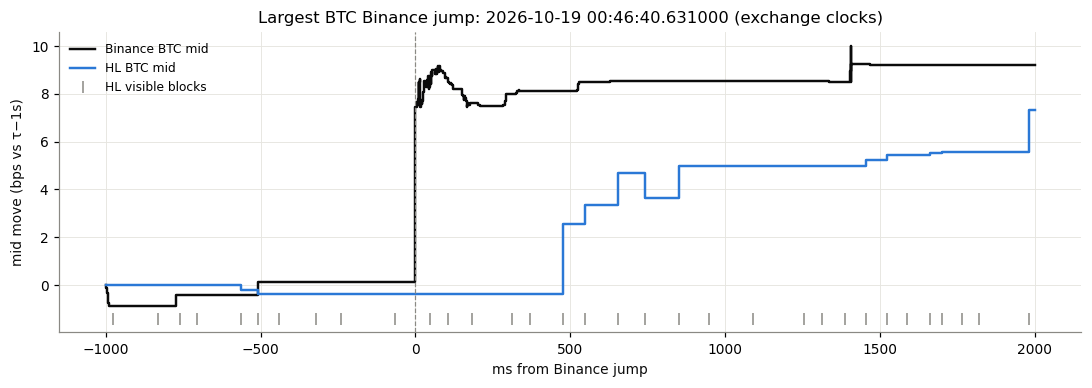

In [29]:
s = "BTC-USD-PERP"
bn, hl = STREAMS[f"bn_l1:{s}"], STREAMS[f"hl_l1:{s}"]
r_all = (bn.lmid_at(evt[s]["tau"]) - bn.lmid_at(evt[s]["tau"] - EVT_RET_MS)) * 1e4
tau0 = evt[s]["tau"][np.nanargmax(np.abs(r_all))]
lo, hi = tau0 - 1000, tau0 + 2000
fig, ax = plt.subplots(figsize=(10, 3.6))
for st, col, lab in [(bn, C_INK, "Binance BTC mid"), (hl, C_CRYPTO, "HL BTC mid")]:
    m = (st.tm >= lo) & (st.tm <= hi)
    tt = np.concatenate([[lo], st.tm[m], [hi]]).astype(float)
    yy = np.concatenate([[st.lmid_at(lo)], st.lm[m], [st.lmid_at(hi)]])
    ax.step(tt - tau0, (yy - st.lmid_at(tau0 - 1000)) * 1e4, where="post", color=col, lw=1.6, label=lab)
bt = blk.t.values[(blk.t.values >= lo) & (blk.t.values <= hi)]
ax.plot(bt - tau0, np.full(len(bt), ax.get_ylim()[0]), "|", color=C_MUTED, ms=8, label="HL visible blocks")
ax.axvline(0, color=C_MUTED, lw=0.8, ls="--")
ax.set(xlabel="ms from Binance jump", ylabel="mid move (bps vs τ−1s)",
       title=f"Largest BTC Binance jump: {pd.to_datetime(tau0, unit='ms')} (exchange clocks)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 10. Instrument-type summary (crypto vs tradfi)

In [30]:
summ = pd.DataFrame({
    "group": {s: GROUP[s] for s in SYMS},
    "visible blocks share": q1_inst["share of all blocks visible"],
    "median gap ms": q1_inst["median gap ms"],
    "rho1 raw gap": {s: q2_inst.loc[(s, GROUP[s]), ("rho(1)", "raw gap")] for s in SYMS},
    "rho1 single-block": {s: q2_inst.loc[(s, GROUP[s]), ("rho(1)", "single-block gap")] for s in SYMS},
    **{f"Q5 F3 skill [{ln}]": q5_all[(q5_all.features == "F3 +Binance") & (q5_all.latency == ln)].set_index("set")["skill vs F0"]
       for ln in LATENCY_SCENARIOS},
    **{f"Q5 Binance gain [{ln}]": q5_all[(q5_all.features == "F3 +Binance") & (q5_all.latency == ln)].set_index("set")["gain vs prev set"]
       for ln in LATENCY_SCENARIOS},
    "event-study lag ms": evt_tab["lag (HL−Binance) ms"],
    "hazard rel. gain": haz["rel. improvement"],
    "lead peak shift ms": peak["peak shift ms"], "lead peak corr": peak["peak corr"],
    "within-gap OOS R2 (δ=10)": lead_tab.xs(10, level="delta ms")["OOS R2"],
}).loc[SYMS]
summ

,group,visible blocks share,median gap ms,rho1 raw gap,rho1 single-block,"Q5 F3 skill [N(0.50, 0.05) ms]",Q5 F3 skill [measured ts_recv],"Q5 Binance gain [N(0.50, 0.05) ms]",Q5 Binance gain [measured ts_recv],event-study lag ms,hazard rel. gain,lead peak shift ms,lead peak corr,within-gap OOS R2 (δ=10)
BTC-USD-PERP,crypto,0.4098,112.0,0.234,-0.203,0.1629,0.1366,0.0208,0.0226,540.0,1.4838e-03,-490.0,0.3024,0.0056
HYPE-USD-PERP,crypto,0.3341,122.0,0.258,-0.194,0.1627,0.1420,0.0411,0.0472,290.0,3.0740e-03,-230.0,0.2231,0.0399
AAVE-USD-PERP,crypto,0.1977,140.0,0.184,-0.210,0.1712,0.1661,0.0662,0.0669,350.0,1.0407e-02,-180.0,0.4081,0.1003
xyz:SP500-USD-PERP,tradfi,0.1359,199.0,0.279,-0.179,0.2466,0.2412,0.0104,0.0131,610.0,6.1000e-05,-200.0,0.3070,0.0458
xyz:TSLA-USD-PERP,tradfi,0.1158,147.0,0.275,-0.190,0.2704,0.2607,0.0427,0.0421,370.0,1.0924e-02,220.0,0.4070,0.0964
xyz:CL-USD-PERP,tradfi,0.1641,136.0,0.268,-0.177,0.2833,0.2560,0.0549,0.0550,450.0,7.8965e-03,-200.0,0.3772,0.0385


## 11. Trials

In [31]:
print(f"n_trials (model variants evaluated in this notebook): {len(TRIALS)}")
pd.DataFrame(TRIALS).groupby("q").size()

n_trials (model variants evaluated in this notebook): 155


q
Q-hazard    14
Q-lead      18
Q1           4
Q3          63
Q4          14
Q5          42
dtype: int64

## 12. Findings (run of 2026-10-23; 48 h window 10-18 03:14 → 10-20 03:14 UTC, 46.3 h covered; n_trials = 155)

**Weak points first**
* **Not converged: forecast skill levels and everything tradfi.** Between the 7.2 h run (Sunday morning) and this one, the
  union Q5 skill moved from 14.1% to 19.5% (and 10.7% to 12.7% on `ts_recv`), outside the earlier CIs. Tradfi Q4/Q5 roughly
  doubled, and the SP500 and TSLA lead profiles flipped sign. These depend on the session, and this sample has one weekend day
  and one weekday.
* **The train/test split straddles weekend → weekday** (split at Mon 08:16 UTC). F0 is fit on the quieter regime, so
  "skill vs F0" partly measures the regime change. Coverage of the F0 interval on test is 82% (nominal 80%), so the shift is
  modest for the union, but not checked per session.
* One window (Sun 03:14 → Tue 03:14 UTC). The US open is partly missing (holes 12:17–13:32 and 14:00–14:24 UTC Monday).
  It contains the 7.2 h sample, so agreement with that run isn't independent.
* There's no block height in the feed, so block counts are *inferred*.
* Q1–Q4, the hazard and the lead analysis are exchange-time descriptions. Only Q5 applies latency.
* The HL↔Binance clock offset is unverified. Every lead/lag number below includes it.
* The Q3 bootstrap CIs ignore autocorrelation (too narrow). At n ≈ 1M, almost every test is "significant", so read magnitudes.

**Converged (7.2 h → 48 h): the block structure.** The 67 ms clock, single-block ρ(1) ≈ −0.20, Q3 null, the timing null
for Binance, the BTC event lag (~540 ms) and which instruments Binance helps most.

**Q1 Distribution.** Every candidate is formally rejected (chi² p ≈ 0, n = 635k test gaps). The best fit is still the lattice:
**a 67.0 ms clock (σ 1.8 ms) carrying 55% of blocks** (65% on Sunday morning), the rest spread over ~45–100 ms. Mean
block 68.3 ms (14.6/s). ~63% of blocks are visible to the 6-instrument union (53% Sunday morning). Exponential is badly wrong.

**Q2 Autocorrelation.** Raw gaps: ρ(1) = 0.17, mostly visibility clustering. The clock: single-block gaps have
**ρ(1) = −0.20 vs −0.001 expected from ms rounding**, and −0.18 to −0.21 on every instrument. A short block is followed by a
longer one (prev ≤ 55 ms → next median 72; prev 80–100 → 65). The clock looks schedule-anchored with catch-up.

**Q3 Activity.** It doesn't move the clock: single-block next-gap medians are 67 vs 67 ms after busy vs quiet blocks (union
AUC 0.485–0.49). A block with a trade in it is itself ~1 ms longer (68 vs 67, AUC 0.52), as in the 7.2 h run; that's at the
1 ms timestamp resolution. The big raw effects are visibility.

**Q4 Lags.** Jointly significant everywhere. OOS R² of log next gap: 0.10 (union), crypto 0.11–0.14, tradfi 0.23–0.29
(0.08–0.22 on Sunday morning). Activity adds 0.005–0.013 OOS R² given lags.

**Q5 Forecast within an interval, with latency.**
* *N(0.50, 0.05) ms (HL only; Binance at exchange time):* identical to zero latency at 1 ms resolution. Union skill vs
  unconditional is **19.5% [19.2, 19.7]**; most of it comes from lags alone (17.4%). The 80% interval covers 80%; the median
  width goes from 137 to 74 ms. Per instrument, crypto 16–17% and tradfi 25–28%.
* *Measured `ts_recv`:* you learn about block n a median **304 ms** after it happened (~4–5 blocks later). The target is the
  residual wait to the next block after that moment (median 48 ms). Union skill drops to **12.7% [12.5, 13.0]**;
  per instrument 14% (BTC) to 26% (TSLA). Coverage 78–80%.
* Binance gain over HL features (N(0.5) / `ts_recv`): AAVE +6.6 / +6.7%, CL +5.5 / +5.5%, TSLA +4.3 / +4.2%,
  HYPE +4.1 / +4.7%, BTC +2.1 / +2.3%, SP500 +1.0 / +1.3%; union +0.9 / +1.0%.

**Binance inside the gap: timing.** The hazard gain is ≤ 1.1% log-loss per instrument (AAVE, TSLA ~1%; BTC 0.15%; SP500 0).
On the union, adding Binance makes the test log-loss slightly *worse* (−0.19%, CI excludes 0). The clock test is
|Spearman ρ| < 0.01 everywhere (nonzero at n ≈ 1M, negligible in size). Binance predicts when an HL *instrument reprices*,
not when the chain commits a block.

**Binance inside the gap: price (§9.3–9.4).** After a Binance jump, HL's mid reaches half the Binance move
**290 ms (HYPE), 350 ms (AAVE), 540 ms (BTC)** later. Tradfi: TSLA 370, CL 450, SP500 610 ms, now on 188–218 jumps each
(3–17 before). By +2 s, HL has caught up 81% (SP500) to ~100%. The within-gap Binance return explains OOS R² 0.10 of the
next HL mid change for AAVE and TSLA, 0.04–0.05 for HYPE/SP500/CL and 0.006 for BTC; sign hit-rate 75–91%. Lead-profile peaks
sit at −180 to −490 ms except TSLA (+220 ms, but the profile is flat: 0.41 at the peak vs 0.38 at 0).
The largest BTC jump (Mon 00:46:40 UTC): HL's BTC mid doesn't move for ~480 ms, then steps up over ~1.5 s and reaches
~60% of the Binance move by +1.9 s. HL blocks keep arriving every ~60–130 ms throughout, so this example shows **no block
stall** (the 7.2 h example had a 130–300 ms hole).

**Crypto vs tradfi.** Same chain clock (80–85% of tradfi timestamps coincide with crypto ones). With a weekday in the
sample, tradfi visibility rose (TSLA 3% → 12% of blocks; BTC 41%), and tradfi gaps became the *more* forecastable ones.
Whether that's the US session or Monday in general isn't separable here.

**Assumptions** (all marked `# ASSUMPTION:` in the code)
* Sample = the first 48 h of capture; the full ~89 h ran out of memory twice on this machine.
* A feed hole = no visible block on any of the 6 instruments for 30 s; segments also break at reconnects and window edges.
* xyz:SP500 ↔ Binance SPY (returns comparable, levels not); xyz:CL ↔ CL-USDT; xyz:TSLA ↔ TSLA-USDT.
* Binance `T` (matching-engine time) is the closest analogue to HL block time.
* Chronological 60/40 split by HL block time, no shuffling.
* Distribution fits use gaps ≤ 600 ms; "single-block" = P(k=1 | gap) ≥ 0.90 under the train fit (cut = 100 ms).
* k (invisible blocks per gap) is independent of block durations (not exactly true; k-weights are descriptive).
* "High activity" = top quintile of the train activity measure.
* Gradient boosting hyperparameters fixed and untuned.
* `measured ts_recv` assumes the VM and exchange clocks are in sync.
* Event-study jump = top 0.5% of |50 ms Binance return| per pair (full-sample quantile), jumps ≥ 2 s apart.

**Open questions for Mark**
1. The ~200 ms floor on HL `ts_recv − ts_exch` (median staleness now 304 ms) rules out 0.5 ms end-to-end. Is the 0.5 ms you
   heard about something else, e.g. block-commit → publish inside the node?
2. Do you want to test the "phase-locked 67 ms grid with catch-up" idea directly? What would falsify it?
3. Block stalls after large moves: the 48 h largest BTC jump shows none. Still worth testing on the union stream, or drop it?
4. For the non-converged parts (skill levels, tradfi), which split do you believe is the right one: day by day,
   weekday vs weekend, or US cash session vs not? (Like question 6 in `hl_mm_baseline`.) And should train/test be split
   within each day rather than across the weekend → weekday boundary?
5. On the union, Binance features made the hazard model slightly worse out of sample. Is that worth a look, or is the
   per-instrument view the only one you care about?